# 32. Matched checkpoint comparison: calibration, observability, and single-sensor rollouts

**Inference-only** comparison of `002.10` (calibration-only) versus `002.15` (joint correction + observability prediction). Change two checkpoint paths in Section 2 to compare future runs.

1. Original matched ± Student-t regression, kept unchanged for checkpoint compatibility.
2. Joint-head prediction of **Jacobian/Fisher-information-based observability scores** on nominal held-out windows. These are mapped scores computed from a manually constructed measurement Jacobian and Fisher information matrix, **not** outputs from a factor graph optimizer.
3. **Isolated one-step tests:** rotation-only along X/Y/Z from **0° upward**, rotation + positive/negative tau error, and tau-only errors. Both perturbation signs are tested.
4. **One-sensor-at-a-time rollouts:** exactly one sensor's initial calibration is perturbed. The default diagnostic updates **only that sensor**, keeping both other sensor calibrations fixed. Rotation-only cases hold all clocks fixed; combined cases may update rotation and tau of the faulty sensor; tau-only cases only update that clock.
5. Predicted observability curves, temporal drift, and convergence summaries. A good one-step correlation is not evidence of rollout convergence.

**Conventions:** left-multiplied SO(3) corrections and geodesic rotation error. Translation is frozen because its correction head was not trained. The auxiliary observability head predicts scores but does **not** directly gate calibration updates. The cached observability targets refer to nominal windows; predictions evaluated at wrong priors need not coincide with them.


## 1. Imports and local repository setup

In [1]:
from pathlib import Path
import sys
import inspect
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.observability.estimators import ObservabilityMatrixEstimator
from obscalib.observability.layout import CalibrationParameterLayout
from obscalib.observability.mappings import dimensionless_soft_projector_observability
from obscalib.observability.numerics import ObservabilityNumericsConfig
from obscalib.observability.structures import ObservabilityResult
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger
import gc

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)

Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Experiment configuration and interchangeable checkpoints

Change only `BASELINE_CHECKPOINT` and `OBSERVABILITY_CHECKPOINT` for the future `002.16` comparison. The latter must be a **joint wrapper** checkpoint with both `calibration_model` and `observability_head`.

In [2]:
RUN_NAME = "comparison_002.17_vs_002.15"

# Specify the exact previous successful checkpoint; this is a weights-only initialization.
# Change SOURCE_RUN_NAME to "kaist_pooled_calibration_paired_002.9_student" if that is your actual saved run directory.
# BASELINE_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_paired_002.10_fine_coarse" / "best.pt"
# BASELINE_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_paired_002.16_correction_only" / "best.pt"
BASELINE_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_paired_002.17_large_angle_fine_coarse" / "best.pt"
OBSERVABILITY_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_paired_002.15_observability_output" / "joint_best.pt"

# For later comparisons, for example:
# BASELINE_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_paired_002.16_correction_only" / "best.pt"
# OBSERVABILITY_CHECKPOINT = ROOT / "runs" / "<new_joint_run>" / "joint_best.pt"
RESUME_CHECKPOINT = BASELINE_CHECKPOINT

RANDOM_SEED = 12345
TRAIN_PAIR_SEED = 23456
VALIDATION_PAIR_SEED = 34567
TEST_PAIR_SEED = 45678
VISUALIZATION_PAIR_SEED = 56789

DEVICE_NAME = "cuda"
DEVICE = torch.device("cuda" if DEVICE_NAME == "auto" and torch.cuda.is_available() else DEVICE_NAME)
MODEL_DTYPE = torch.float32

CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
CALIBRATION_CONTEXT_DIM = 7

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700

BATCH_SIZE = 16
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

NUM_EPOCHS = 50  # Calibration fine-tuning limit; frozen probe uses PROBE_EPOCHS
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
CHECKPOINT_EVERY_EPOCHS = 3
PRINT_EVERY_BATCHES = 500
LR_REDUCTION_FACTOR = 0.5
LR_PATIENCE_EPOCHS = 8

MEASUREMENT_DIM = 6
BASE_TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2
OBSERVABILITY_TOKEN_FEATURE_DIM = 7
TOKEN_INPUT_DIM = BASE_TOKEN_INPUT_DIM  # No observability input channels in notebook 31
OBSERVABILITY_CACHE_DIR = ROOT / "outputs" / "observability_targets" / "three_sensor"
LEGACY_OBSERVABILITY_CACHE_DIR = ROOT / "outputs" / "observability_targets"  # Read-only legacy-cache lookup.
OBSERVABILITY_SOURCE = "scientific_soft_projector_cached_or_computed"
# Cache method and numerical settings follow notebook 11. Missing/incompatible three-sensor caches are rebuilt.
OBSERVABILITY_CACHE_VERSION = 1  # Keep compatible with the latest executed notebook 30 caches; do not force a rebuild.
REFERENCE_LIDAR_STREAM_KEY = "lidar"
USE_NJIT_OBSERVABILITY = True
PROJECTION_NUMERICAL_TOLERANCE = 1e-10
DIMENSIONLESS_ROTATION_SCALE_RAD = np.deg2rad(5.0)
DIMENSIONLESS_TRANSLATION_SCALE_M = 0.05
DIMENSIONLESS_TIME_OFFSET_SCALE_S = 0.015
DIMENSIONLESS_CALIBRATION_SCALE = (
    DIMENSIONLESS_ROTATION_SCALE_RAD, DIMENSIONLESS_ROTATION_SCALE_RAD, DIMENSIONLESS_ROTATION_SCALE_RAD,
    DIMENSIONLESS_TRANSLATION_SCALE_M, DIMENSIONLESS_TRANSLATION_SCALE_M, DIMENSIONLESS_TRANSLATION_SCALE_M,
    DIMENSIONLESS_TIME_OFFSET_SCALE_S,
)
LAMBDA_VALUE_SETTING = 0.25
D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 12
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.0
NUM_SUMMARY_TOKENS = 1

POOLER_N_HEADS = 8
POOLER_DROPOUT = 0.0
MLP_HIDDEN_DIMS = (256, 128)
SHARED_FEATURE_DIM = 128
MLP_DROPOUT = 0.0
HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.0

CORRECTION_LOSS_TYPE = "mse"
ROTATION_LOSS_SCALE_RAD = np.deg2rad(5.0)
TRANSLATION_LOSS_SCALE_M = 0.05
TIME_OFFSET_LOSS_SCALE_S = 0.050
ROTATION_LOSS_WEIGHT = 2.0
TRANSLATION_LOSS_WEIGHT = 1.0
TIME_OFFSET_LOSS_WEIGHT = 1.0
PAIR_LOSS_WEIGHT = 0.1
TRUTH_ANCHOR_LOSS_WEIGHT = 1.0   # Truth branch is not executed, so contributes zero.
CHANGE_EVENT_LOSS_WEIGHT = 0.0
CHANGE_TIME_LOSS_WEIGHT = 0.0

# Canonical single Student-t prior distribution, not a fine/coarse mixture.
PAIR_ROTATION_MAX_RAD = np.deg2rad(60.0)
PAIR_ROTATION_SCALE_RAD = np.deg2rad(30.0)
PAIR_TIME_OFFSET_MAX_S = 0.500
PAIR_TIME_OFFSET_SCALE_S = 0.250
STUDENT_T_DEGREES_OF_FREEDOM = 3
PAIR_TRANSLATION_MAX_M = 0.02  # Disabled generic prior only; no translation learning.

if not RESUME_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Source checkpoint not found: {RESUME_CHECKPOINT}. Set SOURCE_RUN_NAME to the saved successful run.")

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Run:", RUN_NAME)
print("Calibration baseline:", BASELINE_CHECKPOINT)
print("Observability-aware:", OBSERVABILITY_CHECKPOINT)
print("Calibration order:", CALIBRATION_KEYS)
print(f"Observability: 7D auxiliary output per calibration | token input stays {TOKEN_INPUT_DIM}")
print(f"Canonical prior: rotation max={np.rad2deg(PAIR_ROTATION_MAX_RAD):g}°, scale={np.rad2deg(PAIR_ROTATION_SCALE_RAD):g}°; tau max={PAIR_TIME_OFFSET_MAX_S*1000:g} ms, scale={PAIR_TIME_OFFSET_SCALE_S*1000:g} ms")
print("Cached Jacobian/Fisher-based observability scores are used only as evaluation targets.")




# Evaluation only. Both models see identical data and prior perturbations.
MODEL_LABELS = ("Calibration-only", "Joint + observability")
COMPARE_NUM_WINDOWS = min(256, 699)             # Uniformly spaced held-out windows over Urban38 and Urban39.
COMPARE_BATCH_SIZE = 8
COMPARE_PAIR_SEED = TEST_PAIR_SEED + 321000

# Isolated tests include zero and small rotations: no forced x-axis starting at 45 degrees.
ISOLATED_SEQUENCE = "Urban38"
ISOLATED_WINDOWS = 12  # Increase for tighter confidence intervals; one-step tests can be expensive.
ISOLATED_START = 0
ISOLATED_ANGLES_DEG = (0.0, 2.0, 5.0, 10.0, 20.0, 30.0, 45.0, 60.0, 90.0, 130.0)
ISOLATED_SIGNS = (1.0, -1.0)
ISOLATED_COMBINED_ANGLES_DEG = (10.0, 45.0, 90.0)
ISOLATED_COMBINED_TAU_MS = (-150.0, 150.0)
ISOLATED_TAU_ONLY_MS = (-250.0, -150.0, -75.0, -25.0, 0.0, 25.0, 75.0, 150.0, 250.0)
RUN_COMBINED_ONE_STEP = True
RUN_TAU_ONLY_ONE_STEP = True

ROLLOUT_SEQUENCE = "Urban38"
ROLLOUT_START = 0
ROLLOUT_NUM_WINDOWS = 60
ROLLOUT_INITIAL_ANGLES_DEG = (45.0, 90.0, 130.0)
ROLLOUT_AXES = (0, 1, 2)
ROLLOUT_INITIAL_SIGNS = (1.0,)  # Add -1.0 for sign-asymmetric rollout analysis.
ROLLOUT_MULTI_ROTATION_DEG = ((30.0, -40.0, 20.0), (75.0, -35.0, 40.0))
ROLLOUT_MULTI_TAU_MS = (150.0, -150.0)
ROLLOUT_TAU_ONLY_MS = (-150.0, 150.0)
RUN_MIXED_ROLLOUTS = True
RUN_TAU_ONLY_ROLLOUTS = True

# Isolate estimator behavior before studying deployment-wide coupled updating.
# Exactly one sensor is initially perturbed AND only that sensor is updated.
ROTATION_UPDATE_GAIN = 1.0
TAU_UPDATE_GAIN = 1.0
MAX_ROTATION_UPDATE_DEG = None  # Optional; set e.g. 20.0 for a damped-control ablation.
CONVERGENCE_THRESHOLD_DEG = 5.0
TAU_CONVERGENCE_THRESHOLD_MS = 15.0
CONVERGENCE_STABLE_WINDOWS = 10

SAVE_RESULTS = True
COMPARISON_OUT = ROOT / "runs" / RUN_NAME
if SAVE_RESULTS: COMPARISON_OUT.mkdir(parents=True, exist_ok=True)

if not OBSERVABILITY_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Observability-aware checkpoint missing: {OBSERVABILITY_CHECKPOINT}")
if not (1 <= COMPARE_NUM_WINDOWS): raise ValueError("Select at least one held-out window")
if ROTATION_UPDATE_GAIN <= 0 or TAU_UPDATE_GAIN <= 0: raise ValueError("Invalid rollout gain")
if any(a < 0 or a >= 180 for a in ISOLATED_ANGLES_DEG): raise ValueError("Invalid isolated rotation angles")

# Scientific scores should already exist from notebooks 30/31. Set True only to explicitly
# build missing train/test caches with the same estimator and mapping as notebook 31.
BUILD_MISSING_OBSERVABILITY_CACHE = False

Run: comparison_002.17_vs_002.15
Calibration baseline: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.17_large_angle_fine_coarse/best.pt
Observability-aware: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.15_observability_output/joint_best.pt
Calibration order: ('imu', 'lidar', 'lidar_right')
Observability: 7D auxiliary output per calibration | token input stays 8
Canonical prior: rotation max=60°, scale=30°; tau max=500 ms, scale=250 ms
Cached Jacobian/Fisher-based observability scores are used only as evaluation targets.


## 3. KAIST rig, splits, and dataset construction

The sensor geometry and data paths match notebook 31. Reuse the same nominal calibrations and windows.

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)

train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())

KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

## 4. Jacobian/Fisher-based observability targets: verified cached values

The two evaluated models **never** receive these cached targets as input. They are used only to evaluate the joint head on nominal windows and to provide reference curves. Missing caches are rejected unless you enable explicit rebuilding above.

In [5]:
from obscalib.calibration.observability_targets import ObservabilityTargetCache
from obscalib.calibration.context import calibration_state_to_context

OBSERVABILITY_PARAMETER_NAMES = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")
calibration_layout = CalibrationParameterLayout.from_calibration_keys(CALIBRATION_KEYS)

GYRO_MEASUREMENT_COVARIANCE = torch.tensor([[2.96367932e-06, -1.94438078e-07, -4.83643437e-07], 
                                            [-1.94438078e-07, 1.89162212e-06, 1.09062693e-07], 
                                            [-4.83643437e-07, 1.09062693e-07, 1.88843506e-06]], dtype=torch.float64)
ACCEL_MEASUREMENT_COVARIANCE = torch.tensor([[4.85003041e-03, -9.25262862e-05, 2.14219676e-04], 
                                             [-9.25262862e-05, 1.51980006e-03, -1.13182999e-03], 
                                             [2.14219676e-04, -1.13182999e-03, 2.29777687e-03]], dtype=torch.float64)
LIDAR_SCAN_TO_MAP_ROTATION_COVARIANCE = torch.tensor([[1.10442767e-05, 9.46809587e-07, 3.78536515e-06], 
                                                      [9.46809587e-07, 3.35041997e-05, 1.90008728e-06], 
                                                      [3.78536515e-06, 1.90008728e-06, 1.10553483e-05]], dtype=torch.float64)
LIDAR_SCAN_TO_MAP_TRANSLATION_COVARIANCE = torch.tensor([[0.00843466, 0.00266052, 0.00702046], 
                                                         [0.00266052, 0.01444850, 0.00225705], 
                                                         [0.00702046, 0.00225705, 0.00704268]], dtype=torch.float64)
LIDAR_SCAN_TO_MAP_COVARIANCE = torch.zeros((6, 6), dtype=torch.float64)
LIDAR_SCAN_TO_MAP_COVARIANCE[:3, :3] = LIDAR_SCAN_TO_MAP_ROTATION_COVARIANCE
LIDAR_SCAN_TO_MAP_COVARIANCE[3:, 3:] = LIDAR_SCAN_TO_MAP_TRANSLATION_COVARIANCE
LIDAR_RELATIVE_RESIDUAL_COVARIANCE = 2.0 * LIDAR_SCAN_TO_MAP_COVARIANCE

residual_covariance_by_stream = {"gyro": GYRO_MEASUREMENT_COVARIANCE, "accel": ACCEL_MEASUREMENT_COVARIANCE, "lidar": LIDAR_RELATIVE_RESIDUAL_COVARIANCE, "lidar_right": LIDAR_RELATIVE_RESIDUAL_COVARIANCE}
GRAVITY_WORLD = torch.tensor([0.0, 0.0, 9.81], dtype=torch.float64)
gyro_bias_by_calibration_key = {"imu": torch.zeros(3, dtype=torch.float64)}
observability_numerics = ObservabilityNumericsConfig(relative_tolerance=PROJECTION_NUMERICAL_TOLERANCE, parameter_scales=None)


def relative_lidar_body_trajectory_provider(measurements, metadata, calibration, reference_timebase):
    # The observability estimator can select either LiDAR as its reference timebase.
    # The trajectory must be reconstructed using the selected stream and its extrinsic.
    stream_key = reference_timebase.stream_key

    if stream_key not in ("lidar", "lidar_right"):
        raise ValueError(f"Expected a LiDAR reference stream, got {stream_key!r}.")
    if stream_key not in measurements or stream_key not in metadata:
        raise KeyError(f"Missing reference LiDAR stream {stream_key!r}.")

    stream = measurements[stream_key]
    if stream.interval_start_timestamps is None:
        raise ValueError("Reference LiDAR stream must carry interval_start_timestamps.")

    calibration_key = metadata[stream_key].calibration_key
    T_B_L_current = calibration[calibration_key].transform
    if T_B_L_current.ndim == 3:
        if T_B_L_current.shape[0] != 1:
            raise ValueError("Unbatched trajectory provider expects one calibration state.")
        T_B_L_current = T_B_L_current[0]

    T_B_L_current = T_B_L_current.to(device="cpu", dtype=torch.float64)
    T_L_B_current = torch.linalg.inv(T_B_L_current)
    relative_lidar_poses = stream.values
    interval_starts = stream.interval_start_timestamps
    interval_ends = stream.timestamps

    if relative_lidar_poses.ndim == 4:
        if relative_lidar_poses.shape[0] != 1:
            raise ValueError("Trajectory provider expects an unbatched stream or singleton batch.")
        relative_lidar_poses = relative_lidar_poses[0]
        interval_starts = interval_starts[0]
        interval_ends = interval_ends[0]

    relative_lidar_poses = relative_lidar_poses.to(device="cpu", dtype=torch.float64)
    interval_starts = interval_starts.to(device="cpu", dtype=torch.float64)
    interval_ends = interval_ends.to(device="cpu", dtype=torch.float64)
    reference_timestamps = reference_timebase.timestamps.to(device="cpu", dtype=torch.float64)

    poses_by_time = {}
    current_pose = torch.eye(4, dtype=torch.float64)
    for interval_index in range(relative_lidar_poses.shape[0]):
        start_time = float(interval_starts[interval_index].item())
        end_time = float(interval_ends[interval_index].item())
        poses_by_time[start_time] = current_pose
        current_pose = current_pose @ (T_B_L_current @ relative_lidar_poses[interval_index] @ T_L_B_current)
        poses_by_time[end_time] = current_pose

    available_times = np.asarray(sorted(poses_by_time), dtype=float)
    trajectory_poses = []
    for timestamp in reference_timestamps:
        query_time = float(timestamp.item())
        nearest_index = int(np.argmin(np.abs(available_times - query_time)))
        nearest_time = float(available_times[nearest_index])
        if abs(nearest_time - query_time) > 1e-6:
            raise ValueError(f"Could not construct nominal pose at reference timestamp {query_time:.9f}; nearest available time is {nearest_time:.9f}.")
        trajectory_poses.append(poses_by_time[nearest_time])

    return torch.stack(trajectory_poses, dim=0)


estimator_signature = inspect.signature(ObservabilityMatrixEstimator.__init__)
estimator_kwargs = {"calibration_layout": calibration_layout, "trajectory_provider": relative_lidar_body_trajectory_provider, "residual_covariance_by_stream": residual_covariance_by_stream}
optional_estimator_kwargs = {"gravity_world": GRAVITY_WORLD, "gyro_bias_by_calibration_key": gyro_bias_by_calibration_key, "numerics": observability_numerics, "njit": USE_NJIT_OBSERVABILITY, "reference_stream_key": REFERENCE_LIDAR_STREAM_KEY}
for argument_name, argument_value in optional_estimator_kwargs.items():
    if argument_name in estimator_signature.parameters:
        estimator_kwargs[argument_name] = argument_value

missing_required_arguments = [name for name, parameter in estimator_signature.parameters.items() if name != "self" and parameter.kind in {inspect.Parameter.POSITIONAL_ONLY, inspect.Parameter.POSITIONAL_OR_KEYWORD, inspect.Parameter.KEYWORD_ONLY} and parameter.default is inspect.Parameter.empty and name not in estimator_kwargs]
if missing_required_arguments:
    raise RuntimeError(f"ObservabilityMatrixEstimator has required constructor arguments not configured here: {missing_required_arguments}. Signature: {estimator_signature}")

observability_estimator = ObservabilityMatrixEstimator(**estimator_kwargs)
print("Calibration dimension:", calibration_layout.total_dimension)
print("Estimator signature:", estimator_signature)


##################################################
# Observability target cache: compute / save / load
##################################################

# Cache version and path are configured in experiment parameters.
OBSERVABILITY_CACHE_DIR.mkdir(parents=True, exist_ok=True)


def call_observability_estimator(window):
    forward_signature = inspect.signature(observability_estimator.forward)

    if "metadata" in forward_signature.parameters:
        return observability_estimator(window.streams, window.current_calibration, window.metadata)

    return observability_estimator(window.streams, window.current_calibration)


def make_target_cache_metadata(dataset, *, split_name: str) -> dict:
    """Build metadata used to reject stale or incompatible cached targets."""

    if hasattr(dataset, "sequence_name_for_window"):
        sequence_names = tuple(dataset.sequence_name_for_window(index) for index in range(len(dataset)))
    else:
        sequence_names = None

    return {
        "cache_version": OBSERVABILITY_CACHE_VERSION,
        "split_name": split_name,
        "num_windows": len(dataset),
        "sequence_names": sequence_names,
        "calibration_keys": tuple(CALIBRATION_KEYS),
        "window_duration_s": float(WINDOW_DURATION_S),
        "window_stride_s": float(WINDOW_STRIDE_S),
        "max_samples_per_sensor": int(MAX_SAMPLES_PER_SENSOR),
        "dimensionless_calibration_scale": tuple(float(value) for value in DIMENSIONLESS_CALIBRATION_SCALE),
        "lambda_value_setting": float(LAMBDA_VALUE_SETTING),
        "reference_lidar_stream_key": REFERENCE_LIDAR_STREAM_KEY,
        "numerical_relative_tolerance": float(PROJECTION_NUMERICAL_TOLERANCE),
        "score_source": OBSERVABILITY_SOURCE,
    }


def build_target_cache(dataset, *, description: str) -> ObservabilityTargetCache:
    values = torch.empty((len(dataset), len(CALIBRATION_KEYS), 7), dtype=torch.float32, device="cpu")

    observability_estimator.eval()

    with torch.no_grad():
        for dataset_index in tqdm(range(len(dataset)), desc=description):
            window = collate_windows([dataset[dataset_index]])

            try:
                result = call_observability_estimator(window)

                if not isinstance(result, ObservabilityResult):
                    raise TypeError("Observability estimator must return ObservabilityResult.")

                if result.raw is None or not hasattr(result.raw, "fisher_information_matrix"):
                    raise TypeError("ObservabilityResult.raw must expose fisher_information_matrix.")

                fisher = result.raw.fisher_information_matrix

                if fisher.ndim == 3:
                    if fisher.shape[0] != 1:
                        raise ValueError("Singleton cache construction expected one Fisher matrix.")

                    fisher = fisher[0]

                mapped = dimensionless_soft_projector_observability(
                    fisher,
                    calibration_layout,
                    calibration_scale=DIMENSIONLESS_CALIBRATION_SCALE,
                    lambda_value_setting=LAMBDA_VALUE_SETTING,
                )

                coordinate_observability = mapped[0].detach().to(device="cpu", dtype=torch.float32)

                for calibration_index, calibration_key in enumerate(CALIBRATION_KEYS):
                    parameter_slice = calibration_layout.block_for(calibration_key).parameter_slice
                    values[dataset_index, calibration_index] = coordinate_observability[parameter_slice]

            except Exception as error:
                sequence_name = dataset.sequence_name_for_window(dataset_index) if hasattr(dataset, "sequence_name_for_window") else "<unknown>"
                raise RuntimeError(f"Observability target construction failed for dataset index {dataset_index}, sequence {sequence_name!r}.") from error

    if not torch.isfinite(values).all() or ((values < 0) | (values > 1)).any():
        raise ValueError("Computed observability cache must have finite scores in [0, 1].")

    return ObservabilityTargetCache(
        values=values,
        calibration_keys=CALIBRATION_KEYS,
    )


def save_target_cache(cache: ObservabilityTargetCache, cache_path: Path, metadata: dict) -> None:
    """Save CPU observability targets and experiment metadata."""

    cache_path.parent.mkdir(parents=True, exist_ok=True)

    torch.save(
        {
            "values": cache.values.detach().cpu(),
            "calibration_keys": tuple(cache.calibration_keys),
            "metadata": metadata,
        },
        cache_path,
    )


def load_target_cache(cache_path: Path, expected_metadata: dict) -> ObservabilityTargetCache | None:
    """Load a compatible observability cache, or return None if it is stale."""

    if not cache_path.exists():
        return None

    try:
        saved = torch.load(
            cache_path,
            map_location="cpu",
            weights_only=True,
        )
    except Exception as error:
        print(f"Could not load observability cache {cache_path}: {error}")
        print("The cache will be recomputed.")
        return None

    if not isinstance(saved, dict):
        print(f"Ignoring invalid observability cache {cache_path}: expected a dictionary.")
        return None

    if saved.get("metadata") != expected_metadata:
        print(f"Ignoring stale observability cache: {cache_path}")
        return None

    if "values" not in saved or "calibration_keys" not in saved:
        print(f"Ignoring incomplete observability cache: {cache_path}")
        return None

    calibration_keys = tuple(saved["calibration_keys"])

    if calibration_keys != tuple(CALIBRATION_KEYS):
        print(f"Ignoring observability cache with incompatible calibration keys: {cache_path}")
        return None

    try:
        cache = ObservabilityTargetCache(
            values=saved["values"].to(device="cpu", dtype=torch.float32),
            calibration_keys=calibration_keys,
        )
    except Exception as error:
        print(f"Ignoring invalid observability cache {cache_path}: {error}")
        return None

    if cache.values.shape != (expected_metadata["num_windows"], len(CALIBRATION_KEYS), 7):
        print(
            f"Ignoring observability cache with unexpected shape {tuple(cache.values.shape)}: "
            f"expected {(expected_metadata['num_windows'], len(CALIBRATION_KEYS), 7)}."
        )
        return None

    if not torch.isfinite(cache.values).all() or ((cache.values < 0) | (cache.values > 1)).any():
        print(f"Ignoring out-of-range observability cache: {cache_path}")
        return None

    return cache


def load_or_build_target_cache(dataset, *, split_name: str, description: str) -> ObservabilityTargetCache:
    """Load cached targets when compatible, otherwise compute and save them."""

    cache_path = OBSERVABILITY_CACHE_DIR / f"{split_name}.pt"

    metadata = make_target_cache_metadata(
        dataset,
        split_name=split_name,
    )

    cache = load_target_cache(
        cache_path,
        metadata,
    )

    if cache is None:
        legacy_path = LEGACY_OBSERVABILITY_CACHE_DIR / f"{split_name}.pt"
        legacy_cache = load_target_cache(legacy_path, metadata)
        if legacy_cache is not None:
            save_target_cache(legacy_cache, cache_path, metadata)
            cache = legacy_cache
            print(f"Reused compatible legacy cache {legacy_path} -> {cache_path}")

    if cache is not None:
        print(f"Loaded {split_name} observability targets from {cache_path}")
        return cache

    print(f"No compatible {split_name} observability cache found.")
    print(f"Computing targets and saving them to {cache_path}")

    cache = build_target_cache(
        dataset,
        description=description,
    )

    save_target_cache(
        cache,
        cache_path,
        metadata,
    )

    print(f"Saved {split_name} observability targets to {cache_path}")

    return cache

Calibration dimension: 21
Estimator signature: (self, calibration_layout: 'CalibrationParameterLayout', trajectory_provider: 'TrajectoryProvider', residual_covariance_by_stream: 'Mapping[str, torch.Tensor]', *, reference_time_config: 'ReferenceTimeConfig | None' = None, numerics: 'ObservabilityNumericsConfig | None' = None, gravity_world: 'torch.Tensor | None' = None, gyro_bias_by_calibration_key: 'Mapping[str, torch.Tensor] | None' = None, njit: 'bool' = False) -> 'None'


In [6]:
def get_comparison_cache(dataset, split_name):
    expected_metadata = make_target_cache_metadata(dataset, split_name=split_name)
    cache_path = OBSERVABILITY_CACHE_DIR / f"{split_name}.pt"
    cache = load_target_cache(cache_path, expected_metadata)
    if cache is None:
        if not BUILD_MISSING_OBSERVABILITY_CACHE:
            raise FileNotFoundError(f"Missing/incompatible {split_name} observability cache: {cache_path}. Run notebook 31 cache generation, or set BUILD_MISSING_OBSERVABILITY_CACHE=True here.")
        cache = load_or_build_target_cache(dataset, split_name=split_name, description=f"{split_name} observability targets")
    if cache.values.shape != (len(dataset), len(CALIBRATION_KEYS), OBSERVABILITY_TOKEN_FEATURE_DIM):
        raise ValueError(f"Unexpected {split_name} observability tensor: {tuple(cache.values.shape)}")
    return cache

train_target_cache = get_comparison_cache(train_dataset, "train")
test_target_cache = get_comparison_cache(test_dataset, "test")
print("Train observability:", tuple(train_target_cache.values.shape))
print("Test observability: ", tuple(test_target_cache.values.shape))

Train observability: (2006, 3, 7)
Test observability:  (699, 3, 7)


## 5. Original model/tokenizer and both checkpoint loaders

Both architectures have the same measurement Transformer, pooler and correction head. Only the joint model additionally owns the 128 → 128 → 7 observability-output head. Load strict checkpoint states and verify predictions on a real held-out window.

In [7]:
import copy
from dataclasses import asdict
from types import SimpleNamespace
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from obscalib.calibration.context import calibration_state_to_context

source_model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=BASE_TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(n_heads=POOLER_N_HEADS, dropout=POOLER_DROPOUT, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=HEAD_HIDDEN_DIMS, activation="gelu", dropout=HEAD_DROPOUT),
)

source_model = PooledCalibrationModel(source_model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
source_checkpoint = load_training_checkpoint(RESUME_CHECKPOINT, model=source_model, map_location=DEVICE, restore_rng_state=False)
source_model.eval().requires_grad_(False)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)


def calibration_forward(window: WindowBatch, *, backbone=None, calibration=None):
    """Return the original model output and its shared [B,K,128] features; no observability inputs."""
    if backbone is None:
        backbone = source_model
    current_calibration = window.current_calibration if calibration is None else calibration
    canonical = geometry_processor(window.streams, window.metadata, current_calibration)
    tokens = tokenizer(canonical, observability=None)
    if tokens.x.shape[-1] != BASE_TOKEN_INPUT_DIM or tuple(tokens.calibration_keys) != CALIBRATION_KEYS:
        raise ValueError("Unexpected measurement token dimension or calibration order.")
    context = {key: calibration_state_to_context(current_calibration[key]) for key in CALIBRATION_KEYS}
    result = backbone(tokens, context)
    if result.shared_features is None or result.shared_features.shape != (tokens.x.shape[0], len(CALIBRATION_KEYS), SHARED_FEATURE_DIM):
        raise ValueError(f"Expected shared features [B,3,{SHARED_FEATURE_DIM}].")
    return result


class CalibrationWithObservability(nn.Module):
    """Wrap the pretrained correction model and append a shared observability output. No sensor-specific parameters."""

    def __init__(self, calibration_model: PooledCalibrationModel, observability_head: nn.Module):
        super().__init__()
        self.calibration_model = calibration_model
        self.observability_head = observability_head

    def forward(self, tokens, calibration_context=None):
        correction = self.calibration_model(tokens, calibration_context)
        scores = self.observability_head(correction.shared_features)
        return correction, scores


def build_observability_head():
    return nn.Sequential(nn.Linear(SHARED_FEATURE_DIM, PROBE_HIDDEN_DIM), nn.GELU(), nn.Linear(PROBE_HIDDEN_DIM, OBSERVABILITY_TOKEN_FEATURE_DIM), nn.Sigmoid())

In [8]:
# Build and load the two models only once. The joint checkpoint contains a wrapped model state.
PROBE_HIDDEN_DIM = 128  # Same head architecture as notebook 31.
# build_observability_head closes over PROBE_HIDDEN_DIM at call time.

joint_model = CalibrationWithObservability(
    PooledCalibrationModel(source_model_config), build_observability_head()
).to(device=DEVICE, dtype=MODEL_DTYPE)

joint_checkpoint = load_training_checkpoint(
    OBSERVABILITY_CHECKPOINT, model=joint_model, map_location=DEVICE, restore_rng_state=False
)

source_model.eval().requires_grad_(False)
joint_model.eval().requires_grad_(False)

BACKBONES = {
    MODEL_LABELS[0]: source_model,
    MODEL_LABELS[1]: joint_model.calibration_model,
}

@torch.inference_mode()
def inference_both(window):
    """Return correction outputs for each checkpoint and observability output for the joint model."""
    results = {name: calibration_forward(window, backbone=backbone) for name, backbone in BACKBONES.items()}
    scientific_prediction = joint_model.observability_head(results[MODEL_LABELS[1]].shared_features)
    if scientific_prediction.shape != (next(iter(window.streams.values())).values.shape[0], len(CALIBRATION_KEYS), 7):
        raise RuntimeError("Unexpected joint-head observability shape")
    if not torch.isfinite(scientific_prediction).all():
        raise RuntimeError("Nonfinite predicted observability")
    return results, scientific_prediction

with torch.inference_mode():
    smoke = window_batch_to(collate_windows([test_dataset[0], test_dataset[1]]), DEVICE, dtype=MODEL_DTYPE)
    smoke_results, smoke_observability = inference_both(smoke)
    for name, out in smoke_results.items():
        assert out.shared_features.shape == (2, 3, SHARED_FEATURE_DIM), name
        for key in CALIBRATION_KEYS:
            p = out.predictions[key]
            assert torch.isfinite(p.delta_xi).all() and torch.isfinite(p.delta_tau).all()
    assert smoke_observability.shape == (2, 3, 7)
    del smoke, smoke_results, smoke_observability
print("CHECKPOINT COMPATIBILITY / MODEL OUTPUTS: PASS")
print("Baseline epoch:", source_checkpoint.get("epoch"), "Joint epoch:", joint_checkpoint.get("epoch"))

CHECKPOINT COMPATIBILITY / MODEL OUTPUTS: PASS
Baseline epoch: 39 Joint epoch: 116


## 6. Reproducible canonical Student-t paired priors and exact regression metrics

Matched perturbations are generated once and reused for both models. This directly reproduces the original correction-regression loss, including both ± branches and pair difference.

In [9]:
# First augment the physical context once, BEFORE splitting the +/- prior pair.
# The generic prior sampler stays disabled to avoid perturbing the shared truth.
context_augmentation_config = AugmentationConfig(
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True,
        probability=1.0,
        rotation_probability=1.0,
        translation_probability=0.0,
        time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(30.0)),
        time_offset=PerturbationMagnitudeConfig(maximum=0.03),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False, probability=1.0, rotation=PerturbationMagnitudeConfig(maximum=PAIR_ROTATION_MAX_RAD), translation=PerturbationMagnitudeConfig(maximum=PAIR_TRANSLATION_MAX_M), time_offset=PerturbationMagnitudeConfig(maximum=PAIR_TIME_OFFSET_MAX_S), one_calibration_per_sample=True, one_rotation_axis_per_sample=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

# One canonical Student-t sampler for all windows and all three calibration keys.
pair_prior_config = PriorPerturbationConfig(
    enabled=True,
    probability=1.0,
    rotation=PerturbationMagnitudeConfig(
        maximum=PAIR_ROTATION_MAX_RAD,
        distribution=PerturbationDistribution.TRUNCATED_STUDENT_T,
        scale=PAIR_ROTATION_SCALE_RAD,
        degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM,
    ),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(
        maximum=PAIR_TIME_OFFSET_MAX_S,
        distribution=PerturbationDistribution.TRUNCATED_STUDENT_T,
        scale=PAIR_TIME_OFFSET_SCALE_S,
        degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM,
    ),
    one_calibration_per_sample=True,
    one_rotation_axis_per_sample=False,
    one_perturbation_type_per_sample=False,
)
context_augmentation_pipeline = AugmentationPipeline(context_augmentation_config)
pair_prior_perturber = CalibrationPriorPerturber(pair_prior_config)

print("Shared physical/context augmentation:", context_augmentation_config)
print("Canonical paired prior:", pair_prior_config)

Shared physical/context augmentation: AugmentationConfig(sampling_rate=SamplingRateAugmentationConfig(enabled=False, minimum_imu_frequency_hz=None, minimum_lidar_frequency_hz=None, imu_probability=1.0, lidar_probability=1.0), frame_randomization=FrameRandomizationConfig(enabled=False), prior_perturbation=PriorPerturbationConfig(enabled=False, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=1.0471975511965976, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), translation=PerturbationMagnitudeConfig(maximum=0.02, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False), calibration_event=CalibrationEventConfig(enabled

In [12]:
def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)


def clone_window_with_calibration(window: WindowBatch, calibration):
    return WindowBatch(
        streams=dict(window.streams),
        current_calibration=calibration,
        metadata=dict(window.metadata),
        targets=None if window.targets is None else dict(window.targets),
        dataset_indices=window.dataset_indices,
    )


def sample_pair_prior_deltas(true_calibration, *, generator: torch.Generator):
    """Sample exactly one canonical prior perturbation for each physical window."""
    _, delta_xi, delta_tau = pair_prior_perturber(true_calibration, generator=generator)
    return delta_xi, delta_tau


def make_paired_windows(base_window: WindowBatch, *, generator: torch.Generator, return_truth_window: bool = False):
    # Draw the true physical context only once so +/- priors share identical measurements.
    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window
    true_calibration = context_window.current_calibration

    delta_xi_by_key, delta_tau_by_key = sample_pair_prior_deltas(true_calibration, generator=generator)
    positive_prior = apply_prior_perturbation(true_calibration, delta_xi_by_key, delta_tau_by_key)
    negative_prior = apply_prior_perturbation(true_calibration, {key: -value for key, value in delta_xi_by_key.items()}, {key: -value for key, value in delta_tau_by_key.items()})

    positive_window = clone_window_with_calibration(context_window, positive_prior)
    negative_window = clone_window_with_calibration(context_window, negative_prior)
    if return_truth_window:
        return positive_window, negative_window, context_window, delta_xi_by_key, delta_tau_by_key
    return positive_window, negative_window, delta_xi_by_key, delta_tau_by_key


def correction_target(window: WindowBatch, calibration_key: str):
    if window.targets is None:
        raise ValueError("Window has no calibration targets.")
    target = window.targets[calibration_key]
    current_state = window.current_calibration[calibration_key]
    if target.next_transform is None or target.next_time_offset is None:
        raise ValueError(f"Calibration target {calibration_key!r} does not contain the final calibration state.")

    target_delta_transform = target.next_transform @ torch.linalg.inv(current_state.transform)
    target_delta_xi = se3_log(target_delta_transform)
    target_delta_tau = target.next_time_offset - current_state.time_offset
    return target_delta_xi, target_delta_tau

In [11]:
def correction_regression_loss(prediction, target):
    if CORRECTION_LOSS_TYPE == "mse":
        return F.mse_loss(prediction, target)
    if CORRECTION_LOSS_TYPE == "smooth_l1":
        return F.smooth_l1_loss(prediction, target, beta=1.0)
    if CORRECTION_LOSS_TYPE == "l1":
        return F.l1_loss(prediction, target)
    raise ValueError(f"Unknown CORRECTION_LOSS_TYPE={CORRECTION_LOSS_TYPE!r}.")


def compute_training_loss(window, model_output):
    total_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    num_calibrations = 0

    for calibration_key, prediction in model_output.predictions.items():
        target_delta_xi, target_delta_tau = correction_target(window, calibration_key)

        rotation_loss = correction_regression_loss(prediction.delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD, target_delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD)
        translation_loss = correction_regression_loss(prediction.delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        time_offset_loss = correction_regression_loss(prediction.delta_tau / TIME_OFFSET_LOSS_SCALE_S, target_delta_tau / TIME_OFFSET_LOSS_SCALE_S)

        calibration_loss = ROTATION_LOSS_WEIGHT * rotation_loss + TRANSLATION_LOSS_WEIGHT * translation_loss + TIME_OFFSET_LOSS_WEIGHT * time_offset_loss
        total_loss = total_loss + calibration_loss
        num_calibrations += 1

        rotation_error_rad = torch.linalg.vector_norm(prediction.delta_xi[:, :3] - target_delta_xi[:, :3], dim=-1)
        translation_error_m = torch.linalg.vector_norm(prediction.delta_xi[:, 3:] - target_delta_xi[:, 3:], dim=-1)
        time_offset_error_s = torch.abs(prediction.delta_tau[:, 0] - target_delta_tau[:, 0])

        metrics[f"{calibration_key}/rotation_error_deg"] = torch.rad2deg(rotation_error_rad).mean().item()
        metrics[f"{calibration_key}/translation_error_cm"] = (100.0 * translation_error_m).mean().item()
        metrics[f"{calibration_key}/time_offset_error_ms"] = (1000.0 * time_offset_error_s).mean().item()
        metrics[f"{calibration_key}/loss_rotation"] = rotation_loss.detach().item()
        metrics[f"{calibration_key}/loss_translation"] = translation_loss.detach().item()
        metrics[f"{calibration_key}/loss_time_offset"] = time_offset_loss.detach().item()

    if num_calibrations == 0:
        raise ValueError("Model produced no calibration predictions.")

    total_loss = total_loss / num_calibrations
    metrics["loss_total"] = total_loss.detach().item()
    return total_loss, metrics


def compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output):
    total_pair_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    num_calibrations = 0

    for calibration_key in CALIBRATION_KEYS:
        positive_prediction = positive_output.predictions[calibration_key]
        negative_prediction = negative_output.predictions[calibration_key]

        positive_target_xi, positive_target_tau = correction_target(positive_window, calibration_key)
        negative_target_xi, negative_target_tau = correction_target(negative_window, calibration_key)

        predicted_difference_xi = positive_prediction.delta_xi - negative_prediction.delta_xi
        target_difference_xi = positive_target_xi - negative_target_xi
        predicted_difference_tau = positive_prediction.delta_tau - negative_prediction.delta_tau
        target_difference_tau = positive_target_tau - negative_target_tau

        active_rotation_mask = torch.abs(target_difference_xi[:, :3]) > 1e-10

        if torch.any(active_rotation_mask):
            pair_rotation_loss = correction_regression_loss(predicted_difference_xi[:, :3][active_rotation_mask] / ROTATION_LOSS_SCALE_RAD, target_difference_xi[:, :3][active_rotation_mask] / ROTATION_LOSS_SCALE_RAD)
        else:
            pair_rotation_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)

        pair_translation_loss = correction_regression_loss(predicted_difference_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_difference_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        pair_time_offset_loss = correction_regression_loss(predicted_difference_tau / TIME_OFFSET_LOSS_SCALE_S, target_difference_tau / TIME_OFFSET_LOSS_SCALE_S)

        calibration_pair_loss = ROTATION_LOSS_WEIGHT * pair_rotation_loss + TRANSLATION_LOSS_WEIGHT * pair_translation_loss + TIME_OFFSET_LOSS_WEIGHT * pair_time_offset_loss
        total_pair_loss = total_pair_loss + calibration_pair_loss
        num_calibrations += 1

        metrics[f"{calibration_key}/pair_loss_rotation"] = pair_rotation_loss.detach().item()
        metrics[f"{calibration_key}/pair_loss_translation"] = pair_translation_loss.detach().item()
        metrics[f"{calibration_key}/pair_loss_time_offset"] = pair_time_offset_loss.detach().item()

    if num_calibrations == 0:
        raise ValueError("Model produced no calibration predictions.")

    total_pair_loss = total_pair_loss / num_calibrations
    metrics["loss_pair"] = total_pair_loss.detach().item()

    return total_pair_loss, metrics


def compute_paired_objective(positive_window, positive_output, negative_window, negative_output, truth_window=None, truth_output=None):
    positive_loss, positive_metrics = compute_training_loss(positive_window, positive_output)
    negative_loss, negative_metrics = compute_training_loss(negative_window, negative_output)
    pair_loss, pair_metrics = compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output)

    regular_loss = 0.5 * (positive_loss + negative_loss)

    if truth_window is not None or truth_output is not None:
        if truth_window is None or truth_output is None:
            raise ValueError("truth_window and truth_output must either both be provided or both be None.")

        truth_loss, truth_metrics = compute_training_loss(truth_window, truth_output)
    else:
        truth_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
        truth_metrics = {}

    total_loss = regular_loss + PAIR_LOSS_WEIGHT * pair_loss + TRUTH_ANCHOR_LOSS_WEIGHT * truth_loss

    metrics = {
        "loss_total": total_loss.detach().item(),
        "loss_regular": regular_loss.detach().item(),
        "loss_pair": pair_loss.detach().item(),
        "loss_truth": truth_loss.detach().item(),
    }

    for key in positive_metrics:
        if key == "loss_total":
            continue

        metrics[f"positive/{key}"] = positive_metrics[key]
        metrics[f"negative/{key}"] = negative_metrics[key]
        metrics[f"mean/{key}"] = 0.5 * (positive_metrics[key] + negative_metrics[key])

    for key, value in truth_metrics.items():
        if key != "loss_total":
            metrics[f"truth/{key}"] = value

    metrics.update({f"pair/{key}": value for key, value in pair_metrics.items()})

    return total_loss, metrics

In [21]:
def selected_test_indices(count):
    return np.unique(np.linspace(0, len(test_dataset) - 1, min(count, len(test_dataset)), dtype=int))

@torch.inference_mode()
def evaluate_matched_paired():
    pairs = []
    loss_weighted_sums = {name: {"loss_regular": 0.0, "loss_pair": 0.0, "loss_total": 0.0} for name in BACKBONES}
    num_windows = 0
    generator = make_augmentation_generator(COMPARE_PAIR_SEED)
    indices = selected_test_indices(COMPARE_NUM_WINDOWS)
    records = []
    for start in tqdm(range(0, len(indices), COMPARE_BATCH_SIZE), desc="Matched calibration predictions"):
        ix = indices[start:start + COMPARE_BATCH_SIZE]
        original = window_batch_to(collate_windows([test_dataset[int(i)] for i in ix]), DEVICE, dtype=MODEL_DTYPE)
        positive, negative, _, _ = make_paired_windows(original, generator=generator)
        b = len(ix)
        branch_outputs = {}
        for branch, window in (("positive", positive), ("negative", negative)):
            branch_outputs[branch] = {name: calibration_forward(window, backbone=backbone) for name, backbone in BACKBONES.items()}
            for sensor in CALIBRATION_KEYS:
                target_xi, target_tau = correction_target(window, sensor)
                active = (torch.linalg.vector_norm(target_xi[:, :3], dim=-1) > 1e-8) | (target_tau[:, 0].abs() > 1e-8)
                for name, out in branch_outputs[branch].items():
                    prediction = out.predictions[sensor]
                    for i in torch.where(active)[0].tolist():
                        pxi = prediction.delta_xi[i].detach().cpu().numpy()
                        txi = target_xi[i].detach().cpu().numpy()

                        records.append(dict(
                            model=name,
                            sensor=sensor,
                            branch=branch,
                            dataset_index=int(ix[i]),

                            target_phi_x=np.rad2deg(txi[0]),
                            target_phi_y=np.rad2deg(txi[1]),
                            target_phi_z=np.rad2deg(txi[2]),

                            pred_phi_x=np.rad2deg(pxi[0]),
                            pred_phi_y=np.rad2deg(pxi[1]),
                            pred_phi_z=np.rad2deg(pxi[2]),

                            target_rho_x_cm=100.0 * txi[3],
                            target_rho_y_cm=100.0 * txi[4],
                            target_rho_z_cm=100.0 * txi[5],

                            pred_rho_x_cm=100.0 * pxi[3],
                            pred_rho_y_cm=100.0 * pxi[4],
                            pred_rho_z_cm=100.0 * pxi[5],

                            target_tau_ms=float(target_tau[i, 0].item()) * 1000,
                            pred_tau_ms=float(prediction.delta_tau[i, 0].item()) * 1000,
                        ))
        for name in BACKBONES:
            _, m = compute_paired_objective(positive, branch_outputs["positive"][name], negative, branch_outputs["negative"][name])
            for metric in loss_weighted_sums[name]: loss_weighted_sums[name][metric] += float(m[metric]) * b
        num_windows += b
    summary = pd.DataFrame([dict(model=name, windows=num_windows, **{key: x/num_windows for key, x in vals.items()}) for name, vals in loss_weighted_sums.items()])
    return summary, pd.DataFrame(records)

import pandas as pd
paired_summary, paired_points = evaluate_matched_paired()
display(paired_summary.round(5))
if SAVE_RESULTS:
    paired_summary.to_csv(COMPARISON_OUT / "paired_loss_comparison.csv", index=False)
    paired_points.to_csv(COMPARISON_OUT / "paired_correction_points.csv", index=False)

Matched calibration predictions:   0%|          | 0/32 [00:00<?, ?it/s]

,model,windows,loss_regular,loss_pair,loss_total
0,Calibration-only,256,1.67378,14.97571,3.17135
1,Joint + observability,256,0.65875,2.92631,0.95138


## 7. One-step calibration scatter and physical post-update errors

Each panel plots predicted versus true signed correction for **active** sensors, so inactive zeros from the one-sensor sampler cannot inflate correlation. A separate table shows *actual* SO(3) geodesic errors after applying updates.

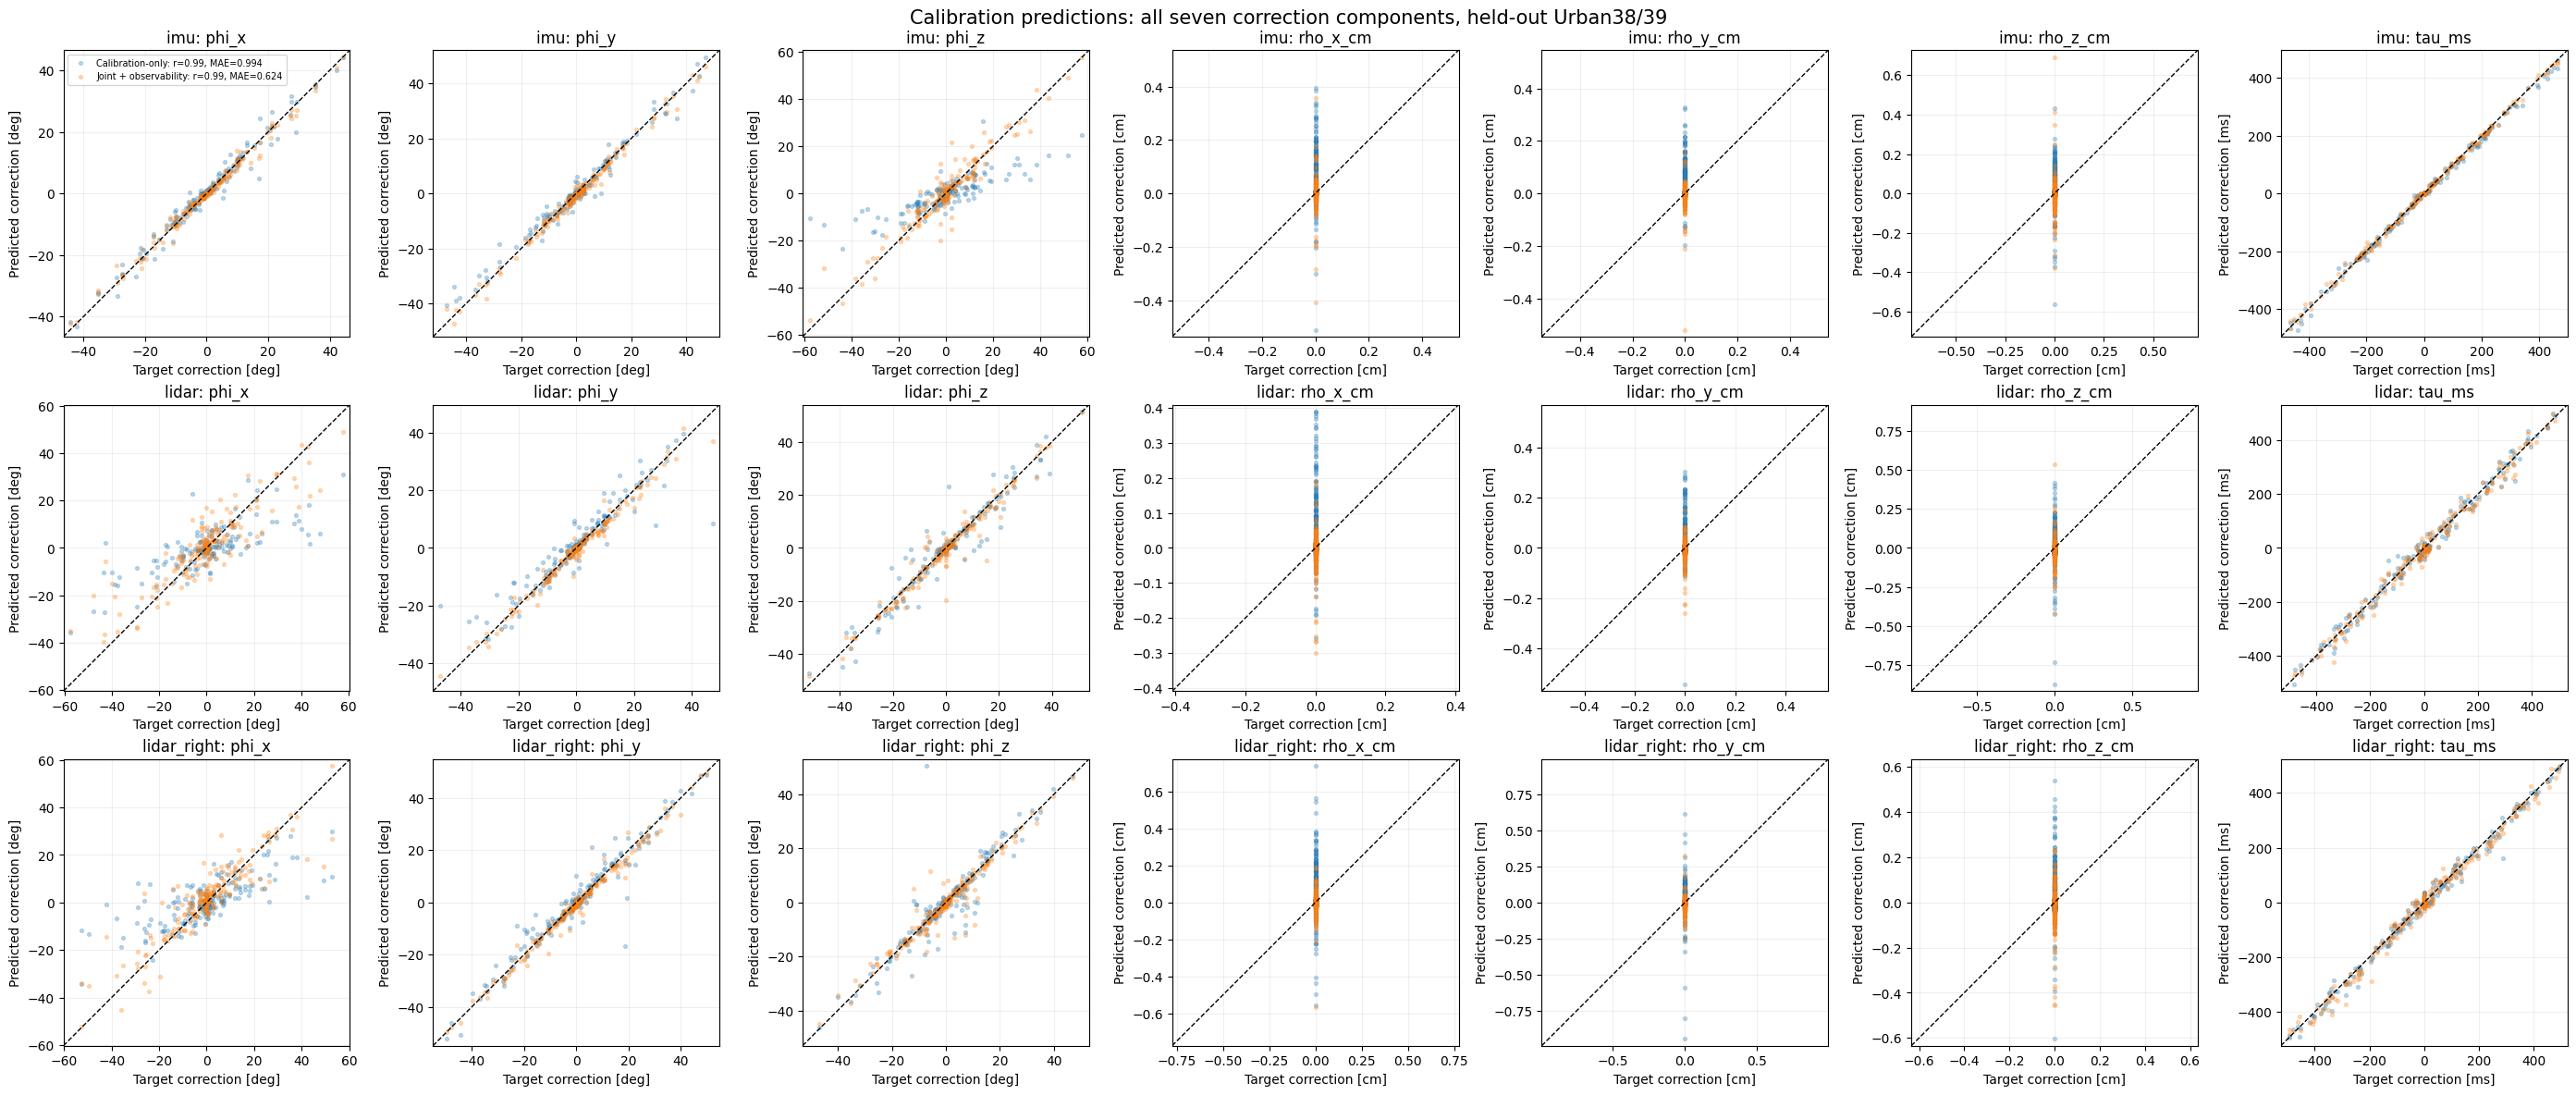

,sensor,dof,model,N,MAE,Pearson
0,imu,phi_x,Calibration-only,288,0.9944,0.9856
1,imu,phi_x,Joint + observability,288,0.6240,0.9947
2,imu,phi_y,Calibration-only,288,1.0846,0.9862
3,imu,phi_y,Joint + observability,288,0.6962,0.9953
4,imu,phi_z,Calibration-only,288,4.0257,0.8387
5,imu,phi_z,Joint + observability,288,1.8672,0.9536
6,imu,rho_x_cm,Calibration-only,288,0.0677,0.0846
7,imu,rho_x_cm,Joint + observability,288,0.0235,0.0272
8,imu,rho_y_cm,Calibration-only,288,0.0512,0.0961
9,imu,rho_y_cm,Joint + observability,288,0.0196,-0.0839


In [22]:
def pearson_safe(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    return float(np.corrcoef(x, y)[0, 1]) if len(x) > 2 and np.std(x) > 1e-9 and np.std(y) > 1e-9 else float("nan")


component_names = ("phi_x", "phi_y", "phi_z", "rho_x_cm", "rho_y_cm", "rho_z_cm", "tau_ms")

fig, axes = plt.subplots(len(CALIBRATION_KEYS), len(component_names), figsize=(28, 12), squeeze=False)
rows = []

for r, key in enumerate(CALIBRATION_KEYS):
    for c, dof in enumerate(component_names):
        ax = axes[r, c]
        extents = []

        unit = "ms" if dof == "tau_ms" else "cm" if dof.startswith("rho_") else "deg"

        for name in BACKBONES:
            group = paired_points[(paired_points.model == name) & (paired_points.sensor == key)]

            truth = group[f"target_{dof}"].to_numpy()
            prediction = group[f"pred_{dof}"].to_numpy()

            mae = np.mean(np.abs(prediction - truth))
            corr = pearson_safe(truth, prediction)

            rows.append(dict(sensor=key, dof=dof, model=name, N=len(truth), MAE=mae, Pearson=corr))

            ax.scatter(truth, prediction, alpha=0.27, s=8, rasterized=True, label=f"{name}: r={corr:.2f}, MAE={mae:.3g}")

            extents.extend((np.max(np.abs(truth)), np.max(np.abs(prediction))))

        # Translation corrections are very small, so zoom independently.
        minimum_limit = 0.001 if dof.startswith("rho_") else 1.0
        lim = max(minimum_limit, max(extents) * 1.05)

        ax.plot([-lim, lim], [-lim, lim], "k--", lw=1)
        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)
        ax.set_aspect("equal", adjustable="box")

        if dof.startswith("rho_"):
            ax.ticklabel_format(axis="both", style="sci", scilimits=(-2, 2))

        ax.set_title(f"{key}: {dof}")
        ax.set_xlabel(f"Target correction [{unit}]")
        ax.set_ylabel(f"Predicted correction [{unit}]")
        ax.grid(alpha=0.2)

        if r == 0 and c == 0:
            ax.legend(fontsize=7)

fig.suptitle("Calibration predictions: all seven correction components, held-out Urban38/39", fontsize=15)
fig.tight_layout()
plt.show()

correlation_table = pd.DataFrame(rows)
display(correlation_table.round(4))

if SAVE_RESULTS:
    correlation_table.to_csv(COMPARISON_OUT / "paired_correction_correlations.csv", index=False)

## 8. Jacobian/Fisher-based observability prediction on unaugmented test windows

Only the observability-aware checkpoint has an observability head. Compare against **held-out Jacobian/Fisher-based targets**, and against the training-set mean. Translation scores have nearly zero variance and must be interpreted separately from the 12 rotation / 3 tau scores.

In [15]:
OBS_SCORE_BATCH_SIZE = 16

@torch.inference_mode()
def collect_nominal_observability():
    prediction = torch.empty_like(test_target_cache.values, dtype=torch.float32)
    seen = torch.zeros(len(test_dataset), dtype=torch.bool)
    loader = make_kaist_dataloader(test_dataset, batch_size=OBS_SCORE_BATCH_SIZE, shuffle=False, drop_last=False, num_workers=0)
    for original in tqdm(loader, desc="Observability head, nominal windows"):
        ix = torch.as_tensor(original.dataset_indices, dtype=torch.long).cpu()
        if seen[ix].any(): raise RuntimeError("Duplicate observability dataset index")
        window = window_batch_to(original, DEVICE, dtype=MODEL_DTYPE)
        result = calibration_forward(window, backbone=joint_model.calibration_model)
        prediction[ix] = joint_model.observability_head(result.shared_features).detach().cpu().float()
        seen[ix] = True
    if not seen.all(): raise RuntimeError("Missing observability predictions")
    return prediction

scientific_observability = test_target_cache.values.float()
predicted_observability = collect_nominal_observability()
train_means = train_target_cache.values.float().mean(dim=0)
obs_rows = []
for k, key in enumerate(CALIBRATION_KEYS):
    for d, dof in enumerate(OBSERVABILITY_PARAMETER_NAMES):
        gt = scientific_observability[:,k,d].numpy()
        pred = predicted_observability[:,k,d].numpy()
        baseline = float(train_means[k,d])
        mse = float(np.mean((pred-gt)**2))
        baseline_mse = float(np.mean((baseline-gt)**2))
        var = float(np.var(gt))
        obs_rows.append(dict(sensor=key, dof=dof, MSE=mse, baseline_MSE=baseline_mse, MAE=float(np.mean(np.abs(pred-gt))),
                             Pearson=pearson_safe(gt,pred), R2=(1-mse/var) if var>1e-10 else np.nan,
                             std_target=np.std(gt), MSE_gain=(baseline_mse-mse)/max(baseline_mse,1e-12)))
obs_table = pd.DataFrame(obs_rows)
display(obs_table.round(5))
print("Mean MSE all 21 DOFs:", obs_table.MSE.mean(), "train mean baseline:", obs_table.baseline_MSE.mean())
meaningful = obs_table[obs_table.dof.isin(("phi_x","phi_y","phi_z","tau"))]
print("Mean MSE for rotation + tau DOFs:", meaningful.MSE.mean(), "train mean baseline:", meaningful.baseline_MSE.mean())
if SAVE_RESULTS:
    obs_table.to_csv(COMPARISON_OUT / "observability_per_dof.csv", index=False)
    torch.save(dict(predicted=predicted_observability, target=scientific_observability, calibration_keys=CALIBRATION_KEYS), COMPARISON_OUT / "observability_predictions.pt")

Observability head, nominal windows:   0%|          | 0/44 [00:00<?, ?it/s]

,sensor,dof,MSE,baseline_MSE,MAE,Pearson,R2,std_target,MSE_gain
0,imu,phi_x,0.00485,0.04357,0.05161,0.93908,0.87097,0.19380,0.88877
1,imu,phi_y,0.00750,0.03771,0.06473,0.89606,0.78786,0.18805,0.80105
2,imu,phi_z,0.00257,0.02289,0.04029,0.94401,0.88365,0.14876,0.88753
3,imu,rho_x,0.00000,0.00000,0.00005,NaN,NaN,0.00000,-216996.68196
4,imu,rho_y,0.00000,0.00000,0.00004,NaN,NaN,0.00000,-131555.87908
5,imu,rho_z,0.00000,0.00000,0.00004,NaN,NaN,0.00000,-162870.69116
6,imu,tau,0.00815,0.09464,0.06766,0.96371,0.90214,0.28850,0.91394
7,lidar,phi_x,0.00393,0.03871,0.04625,0.94667,0.88496,0.18484,0.89847
8,lidar,phi_y,0.00993,0.04509,0.07064,0.88150,0.77616,0.21065,0.77971
9,lidar,phi_z,0.00969,0.03713,0.06430,0.86309,0.73540,0.19135,0.73908


Mean MSE all 21 DOFs: 0.004606229635532107 train mean baseline: 0.026248617922245462
Mean MSE for rotation + tau DOFs: 0.008060171986774852 train mean baseline: 0.045934803473452725


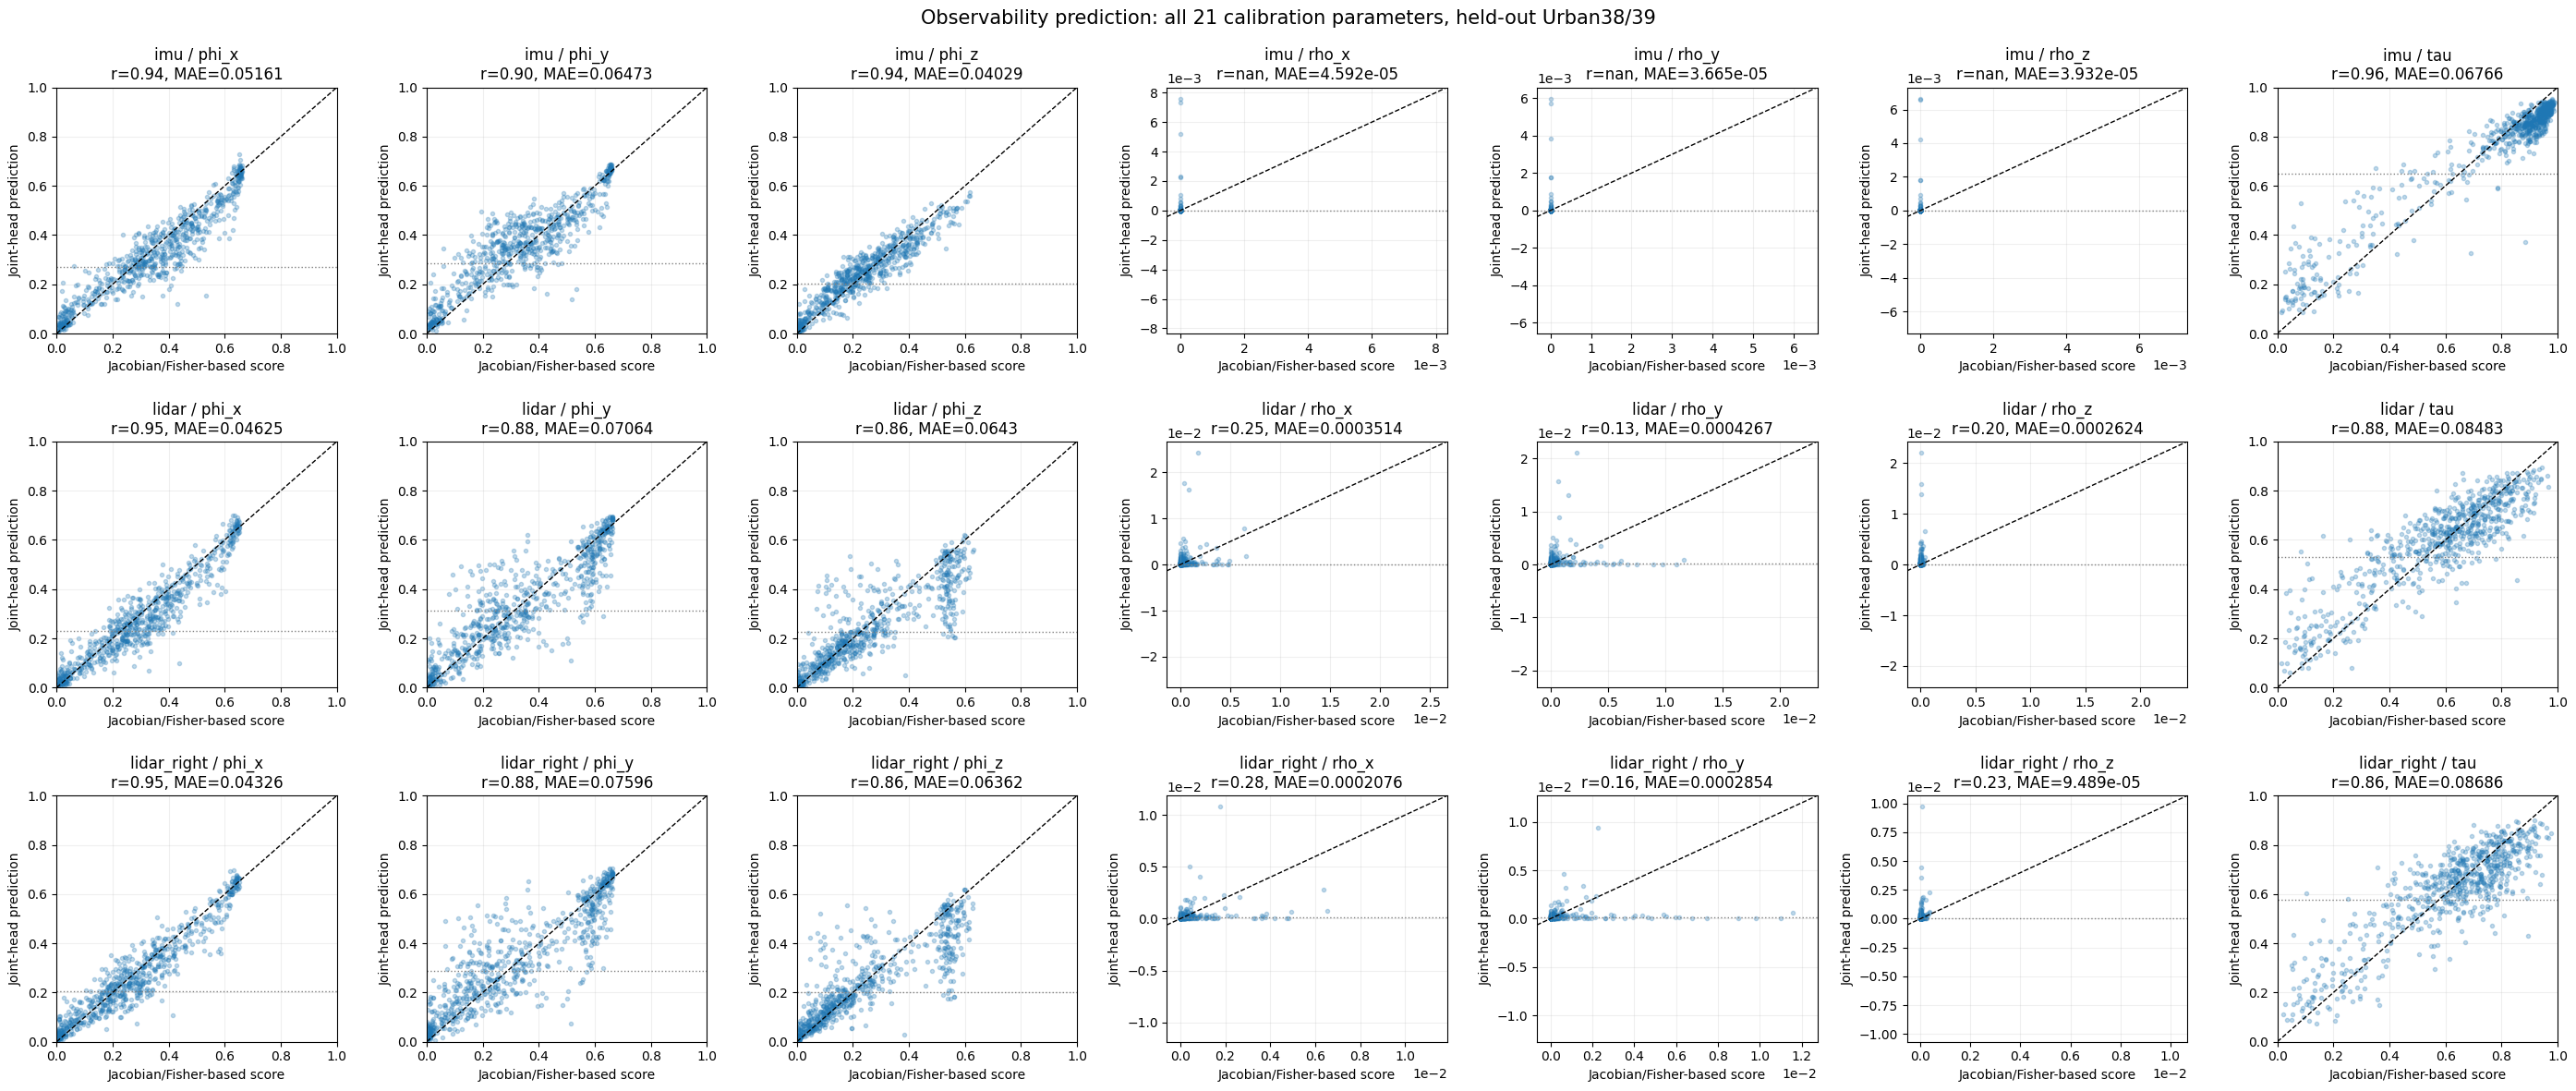

In [20]:
fig, axes = plt.subplots(len(CALIBRATION_KEYS), 7, figsize=(28, 12), squeeze=False)

for k, key in enumerate(CALIBRATION_KEYS):
    for dof_id in range(7):
        ax = axes[k, dof_id]

        truth = scientific_observability[:, k, dof_id].detach().cpu().numpy()
        pred = predicted_observability[:, k, dof_id].detach().cpu().numpy()
        train_mean = float(train_means[k, dof_id])

        corr = pearson_safe(truth, pred)
        mae = np.mean(np.abs(pred - truth))

        ax.scatter(truth, pred, alpha=0.27, s=9, rasterized=True)
        ax.axhline(train_mean, color="gray", ls=":", lw=1, label="Train-mean prediction")

        # Translation observability can be extremely close to zero.
        # Give rho plots their own scale rather than forcing [0, 1].
        if dof_id in (3, 4, 5):
            max_value = max(np.max(np.abs(truth)), np.max(np.abs(pred)), abs(train_mean), 1e-7)
            limit = 1.10 * max_value

            ax.plot([-limit, limit], [-limit, limit], "k--", lw=1)
            ax.set_xlim(-0.05 * limit, limit)
            ax.set_ylim(-limit, limit)
            ax.ticklabel_format(axis="both", style="sci", scilimits=(-2, 2))
        else:
            ax.plot([0, 1], [0, 1], "k--", lw=1)
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)

        ax.set_title(f"{key} / {OBSERVABILITY_PARAMETER_NAMES[dof_id]}\nr={corr:.2f}, MAE={mae:.4g}")
        ax.set_xlabel("Jacobian/Fisher-based score")
        ax.set_ylabel("Joint-head prediction")
        ax.grid(alpha=0.2)

fig.suptitle("Observability prediction: all 21 calibration parameters, held-out Urban38/39", fontsize=15)
fig.tight_layout()
plt.show()

## 9. SO(3) geometry, single-sensor perturbations, and rollout update policy

The initial state differs from the nominal rig **only for one chosen sensor**, even when that sensor has several simultaneous errors. Two healthy sensors are held fixed for the entire rollout. The update selector keeps the non-perturbed DOFs of the faulty sensor fixed too: rotation-only updates rotation; tau-only updates tau; combined updates both. This is an **oracle fault-isolation evaluation policy**, not an automatically deployable fault detector.

Use `gain=1, max_step=None` first to diagnose the raw model. Try damping/clipping afterward as a separate controller experiment. Check pure-axis perturbation at ±2°, ±5°, ±10°, etc. before attributing failures solely to large-angle extrapolation.


In [17]:
from obscalib.geometry.lie import so3_exp
from scipy.spatial.transform import Rotation as SciPyRotation


def so3_geodesic_deg(R_est, R_true):
    """SO(3) geodesic distance in degrees, with stable behavior near the identity."""
    delta = R_true @ R_est.transpose(-1, -2)
    sin_theta = 0.5 * torch.linalg.vector_norm(torch.stack((delta[..., 2, 1] - delta[..., 1, 2], delta[..., 0, 2] - delta[..., 2, 0], delta[..., 1, 0] - delta[..., 0, 1]), dim=-1), dim=-1)
    cos_theta = (delta.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0) * 0.5
    return torch.rad2deg(torch.atan2(sin_theta, cos_theta))


def copy_calibrations(states):
    return {key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for key, state in states.items()}


def perturb_single_sensor_calibration(truth, sensor_key, *, rotation_vector_deg=(0.0, 0.0, 0.0), tau_ms=0.0):
    """Perturb exactly one sensor, optionally in several rotational axes and its clock."""
    if sensor_key not in CALIBRATION_KEYS:
        raise KeyError(sensor_key)
    states = copy_calibrations(truth)
    state = states[sensor_key]
    rotation_vector = torch.as_tensor(rotation_vector_deg, device=state.transform.device, dtype=state.transform.dtype).reshape(1, 3).expand(state.transform.shape[0], -1)
    T = state.transform.clone()
    T[:, :3, :3] = so3_exp(torch.deg2rad(rotation_vector)) @ T[:, :3, :3]
    new_tau = state.time_offset.clone() + float(tau_ms) / 1000.0
    states[sensor_key] = CalibrationState(transform=T, time_offset=new_tau)
    return states


def rotated_initial_calibration(truth, sensor_key, axis, degrees):
    """Backward-compatible isolated-axis wrapper."""
    if not 0 <= axis < 3:
        raise ValueError(axis)
    rotvec = np.zeros(3)
    rotvec[axis] = degrees
    return perturb_single_sensor_calibration(truth, sensor_key, rotation_vector_deg=rotvec)


def apply_target_sensor_update(states, result, sensor_key, *, update_rotation=True, update_tau=False, gain=None, max_step_deg=None):
    """Apply only the faulty sensor's selected DOFs. Never update the two healthy sensors."""
    if sensor_key not in states:
        raise KeyError(sensor_key)
    gain = ROTATION_UPDATE_GAIN if gain is None else gain
    max_step_deg = MAX_ROTATION_UPDATE_DEG if max_step_deg is None else max_step_deg
    updated = copy_calibrations(states)
    state = updated[sensor_key]
    prediction = result.predictions[sensor_key]
    T = state.transform.clone()
    if update_rotation:
        dr = gain * prediction.delta_xi[:, :3]
        if max_step_deg is not None:
            norm = torch.linalg.vector_norm(dr, dim=-1, keepdim=True).clamp_min(1e-12)
            dr = dr * (float(np.deg2rad(max_step_deg)) / norm).clamp(max=1.0)
        T[:, :3, :3] = so3_exp(dr) @ T[:, :3, :3]
    tau = state.time_offset + (TAU_UPDATE_GAIN * prediction.delta_tau if update_tau else 0.0)
    updated[sensor_key] = CalibrationState(transform=T, time_offset=tau)
    return updated


def assert_healthy_sensors_unchanged(initial_states, updated_states, sensor_key):
    for key in CALIBRATION_KEYS:
        if key == sensor_key:
            continue
        torch.testing.assert_close(updated_states[key].transform, initial_states[key].transform, atol=0, rtol=0)
        torch.testing.assert_close(updated_states[key].time_offset, initial_states[key].time_offset, atol=0, rtol=0)


def get_sequence_window_indices(dataset, sequence, first, count):
    indices = list(dataset.window_indices_for_sequence(sequence))
    indices = indices[first:] if count is None else indices[first:first + count]
    if not indices:
        raise ValueError(f"No sequence windows for {sequence}")
    return indices


def prepare_eval_windows(dataset, indices):
    return [window_batch_to(collate_windows([dataset[int(index)]]), DEVICE, dtype=MODEL_DTYPE) for index in indices]


def rotation_error_components(est, gt):
    delta = gt.transform[:, :3, :3] @ est.transform[:, :3, :3].transpose(-1, -2)
    return np.rad2deg(SciPyRotation.from_matrix(delta[0].detach().cpu().numpy()).as_rotvec())


# Geometry and single-fault tests, including identity, rotation-only, and rotation+tau.
with torch.inference_mode():
    window = window_batch_to(collate_windows([test_dataset[0]]), DEVICE, dtype=MODEL_DTYPE)
    for key in CALIBRATION_KEYS:
        for axis in range(3):
            for angle in (0.0, 5.0, 45.0, 130.0):
                states = rotated_initial_calibration(window.current_calibration, key, axis, angle)
                distance = so3_geodesic_deg(states[key].transform[:, :3, :3], window.current_calibration[key].transform[:, :3, :3]).item()
                if abs(distance - angle) > 0.02:
                    raise AssertionError(f"SO(3) perturbation failed: {key}/{axis}/{angle}: {distance}")
                assert_healthy_sensors_unchanged(window.current_calibration, states, key)
        both = perturb_single_sensor_calibration(window.current_calibration, key, rotation_vector_deg=(20.0, -10.0, 30.0), tau_ms=150.0)
        assert_healthy_sensors_unchanged(window.current_calibration, both, key)
        torch.testing.assert_close(both[key].time_offset - window.current_calibration[key].time_offset, torch.full_like(both[key].time_offset, 0.150), atol=1e-6, rtol=0)
print("SO(3) INITIALIZATION / SINGLE-SENSOR FAULT ISOLATION: PASS")


SO(3) INITIALIZATION / SINGLE-SENSOR FAULT ISOLATION: PASS


## 10. Controlled one-step tests: axis-only, axis+tau, and tau-only

Each case uses the **same held-out physical windows** for both checkpoints. Rotation-only errors start at **0°** and include fine, medium, and extrapolation magnitudes. Compare pure-axis errors with combined rotation+tau errors to test the possible training-distribution mismatch. Tau-only tests reveal whether the calibration network can detect a clock error without a simultaneous rotation error.

For each condition we apply only the relevant predicted DOFs of the faulty sensor for the one-step result. This avoids confounding the rotation diagnostic with false tau updates. The correction-only and joint models make raw predictions without clipping or observability-based gating.


In [23]:
isolated_indices = get_sequence_window_indices(test_dataset, ISOLATED_SEQUENCE, ISOLATED_START, ISOLATED_WINDOWS)
isolated_windows = prepare_eval_windows(test_dataset, isolated_indices)


def one_step_case(sensor_key, *, axis=None, signed_deg=0.0, tau_ms=0.0, condition="rotation_only", windows=None):
    """Compute actual SO(3) / tau error for one-sensor perturbations on matched physical windows."""
    if windows is None:
        windows = isolated_windows
    if condition not in ("rotation_only", "rotation_tau", "tau_only"):
        raise ValueError(condition)
    if condition != "tau_only" and axis not in range(3):
        raise ValueError("Rotation diagnostics require a valid axis")
    axis_label = "tau" if axis is None else "xyz"[axis]
    rotation_vector_deg = np.zeros(3)
    if axis is not None:
        rotation_vector_deg[axis] = signed_deg
    values = []
    with torch.inference_mode():
        for window_id, original in enumerate(windows):
            truth = original.current_calibration
            wrong = perturb_single_sensor_calibration(truth, sensor_key, rotation_vector_deg=rotation_vector_deg, tau_ms=tau_ms)
            hypothesis = clone_window_with_calibration(original, wrong)
            results, obs = inference_both(hypothesis)
            for name, result in results.items():
                updated = apply_target_sensor_update(wrong, result, sensor_key, update_rotation=(condition != "tau_only"), update_tau=(condition != "rotation_only"))
                assert_healthy_sensors_unchanged(wrong, updated, sensor_key)
                before_rotation = float(so3_geodesic_deg(wrong[sensor_key].transform[:, :3, :3], truth[sensor_key].transform[:, :3, :3]).item())
                after_rotation = float(so3_geodesic_deg(updated[sensor_key].transform[:, :3, :3], truth[sensor_key].transform[:, :3, :3]).item())
                before_tau = float(1000.0 * (wrong[sensor_key].time_offset - truth[sensor_key].time_offset).abs().mean().item())
                after_tau = float(1000.0 * (updated[sensor_key].time_offset - truth[sensor_key].time_offset).abs().mean().item())
                pred = result.predictions[sensor_key]
                obs_id = 6 if axis is None else axis
                values.append(dict(condition=condition, sensor=sensor_key, axis=axis_label, initial_angle_deg=float(signed_deg), initial_abs_angle_deg=abs(float(signed_deg)), initial_tau_ms=float(tau_ms), model=name, window_id=window_id,
                                   before_deg=before_rotation, after_deg=after_rotation, before_tau_ms=before_tau, after_tau_ms=after_tau,
                                   predicted_update_deg=float(torch.rad2deg(torch.linalg.vector_norm(pred.delta_xi[:, :3], dim=-1)).item()), predicted_tau_ms=float(1000.0 * pred.delta_tau.mean().item()),
                                   improves_rotation=after_rotation < before_rotation - 1e-6, improves_tau=after_tau < before_tau - 1e-5,
                                   predicted_axis_observability=float(obs[0, CALIBRATION_KEYS.index(sensor_key), obs_id].item()) if name == MODEL_LABELS[1] else np.nan))
    return values


rotation_cases = sum(1 if degrees == 0 else len(ISOLATED_SIGNS) for degrees in ISOLATED_ANGLES_DEG)
combined_cases = len(ISOLATED_COMBINED_ANGLES_DEG) * len(ISOLATED_SIGNS) * len(ISOLATED_COMBINED_TAU_MS) if RUN_COMBINED_ONE_STEP else 0
tau_cases = len(ISOLATED_TAU_ONLY_MS) if RUN_TAU_ONLY_ONE_STEP else 0

total_cases = len(CALIBRATION_KEYS) * (3 * (rotation_cases + combined_cases) + tau_cases)

records = []

with tqdm(total=total_cases, desc="Isolated one-step evaluation", unit="case", dynamic_ncols=True) as pbar:
    for sensor in CALIBRATION_KEYS:
        for axis in range(3):
            for degrees in ISOLATED_ANGLES_DEG:
                for sign in ((1.0,) if degrees == 0 else ISOLATED_SIGNS):
                    signed_deg = sign * degrees
                    records.extend(one_step_case(sensor, axis=axis, signed_deg=signed_deg, condition="rotation_only"))
                    pbar.set_postfix(sensor=sensor, axis="xyz"[axis], angle=f"{signed_deg:+g}°", mode="rotation")
                    pbar.update(1)

            if RUN_COMBINED_ONE_STEP:
                for degrees in ISOLATED_COMBINED_ANGLES_DEG:
                    for sign in ISOLATED_SIGNS:
                        for tau_ms in ISOLATED_COMBINED_TAU_MS:
                            signed_deg = sign * degrees
                            records.extend(one_step_case(sensor, axis=axis, signed_deg=signed_deg, tau_ms=tau_ms, condition="rotation_tau"))
                            pbar.set_postfix(sensor=sensor, axis="xyz"[axis], angle=f"{signed_deg:+g}°", tau=f"{tau_ms:+g} ms", mode="combined")
                            pbar.update(1)

        if RUN_TAU_ONLY_ONE_STEP:
            for tau_ms in ISOLATED_TAU_ONLY_MS:
                records.extend(one_step_case(sensor, tau_ms=tau_ms, condition="tau_only"))
                pbar.set_postfix(sensor=sensor, tau=f"{tau_ms:+g} ms", mode="tau")
                pbar.update(1)

isolated_points = pd.DataFrame.from_records(records)
isolated_summary = isolated_points.groupby(["condition", "sensor", "axis", "initial_angle_deg", "initial_tau_ms", "model"], as_index=False).agg(
    before_deg=("before_deg", "mean"), after_deg=("after_deg", "mean"), before_tau_ms=("before_tau_ms", "mean"), after_tau_ms=("after_tau_ms", "mean"),
    improve_rotation_fraction=("improves_rotation", "mean"), improve_tau_fraction=("improves_tau", "mean"), predicted_update_deg=("predicted_update_deg", "mean"))
print("One-step diagnostic cases:", isolated_points.groupby("condition").size().to_dict())
display(isolated_summary.round(3))
if SAVE_RESULTS:
    isolated_points.to_csv(COMPARISON_OUT / "isolated_one_step_points.csv", index=False)
    isolated_summary.to_csv(COMPARISON_OUT / "isolated_one_step_summary.csv", index=False)


Isolated one-step evaluation:   0%|          | 0/306 [00:00<?, ?case/s]

One-step diagnostic cases: {'rotation_only': 4104, 'rotation_tau': 2592, 'tau_only': 648}


,condition,sensor,axis,initial_angle_deg,initial_tau_ms,model,before_deg,after_deg,before_tau_ms,after_tau_ms,improve_rotation_fraction,improve_tau_fraction,predicted_update_deg
0,rotation_only,imu,x,-130.0,0.0,Calibration-only,130.0,9.879,0.0,0.000,1.0,0.0,122.333
1,rotation_only,imu,x,-130.0,0.0,Joint + observability,130.0,127.998,0.0,0.000,1.0,0.0,2.082
2,rotation_only,imu,x,-90.0,0.0,Calibration-only,90.0,3.457,0.0,0.000,1.0,0.0,91.953
3,rotation_only,imu,x,-90.0,0.0,Joint + observability,90.0,50.077,0.0,0.000,1.0,0.0,40.740
4,rotation_only,imu,x,-60.0,0.0,Calibration-only,60.0,4.097,0.0,0.000,1.0,0.0,62.179
...,...,...,...,...,...,...,...,...,...,...,...,...,...
607,tau_only,lidar_right,tau,0.0,75.0,Joint + observability,0.0,0.000,75.0,22.981,0.0,1.0,1.959
608,tau_only,lidar_right,tau,0.0,150.0,Calibration-only,0.0,0.000,150.0,30.561,0.0,1.0,1.763
609,tau_only,lidar_right,tau,0.0,150.0,Joint + observability,0.0,0.000,150.0,18.396,0.0,1.0,2.269
610,tau_only,lidar_right,tau,0.0,250.0,Calibration-only,0.0,0.000,250.0,22.410,0.0,1.0,2.628


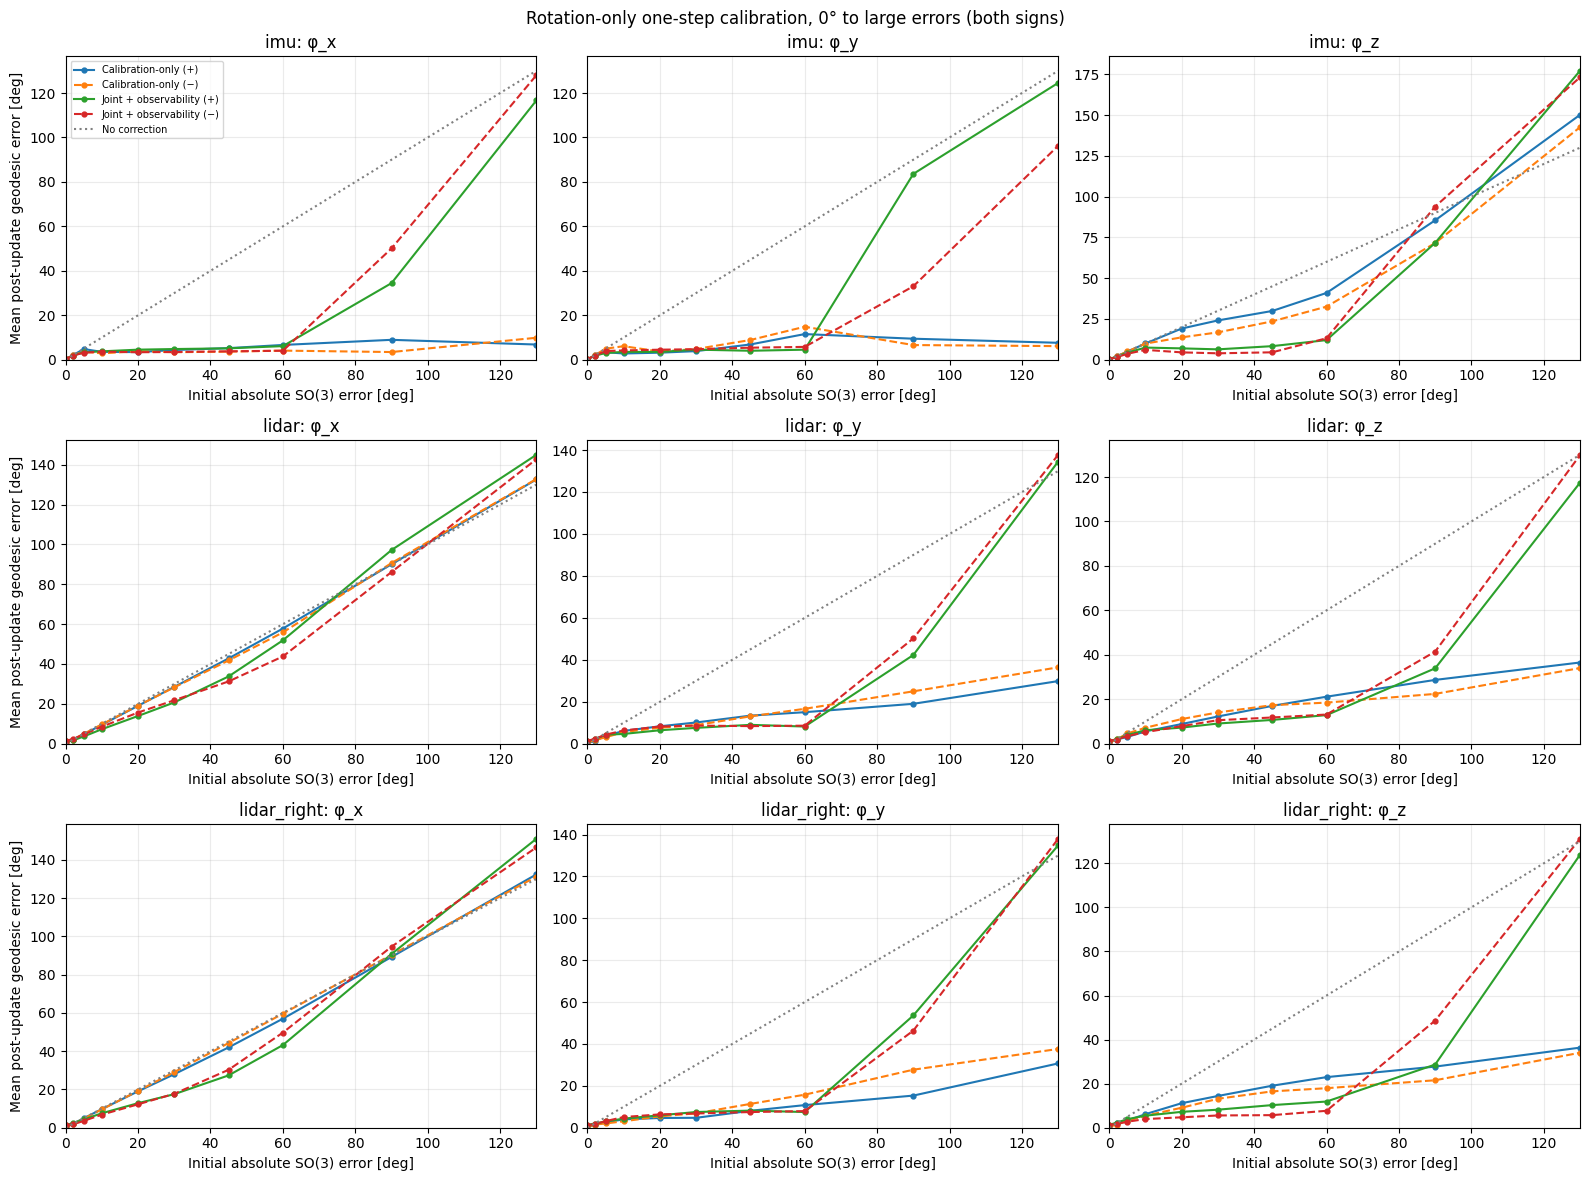

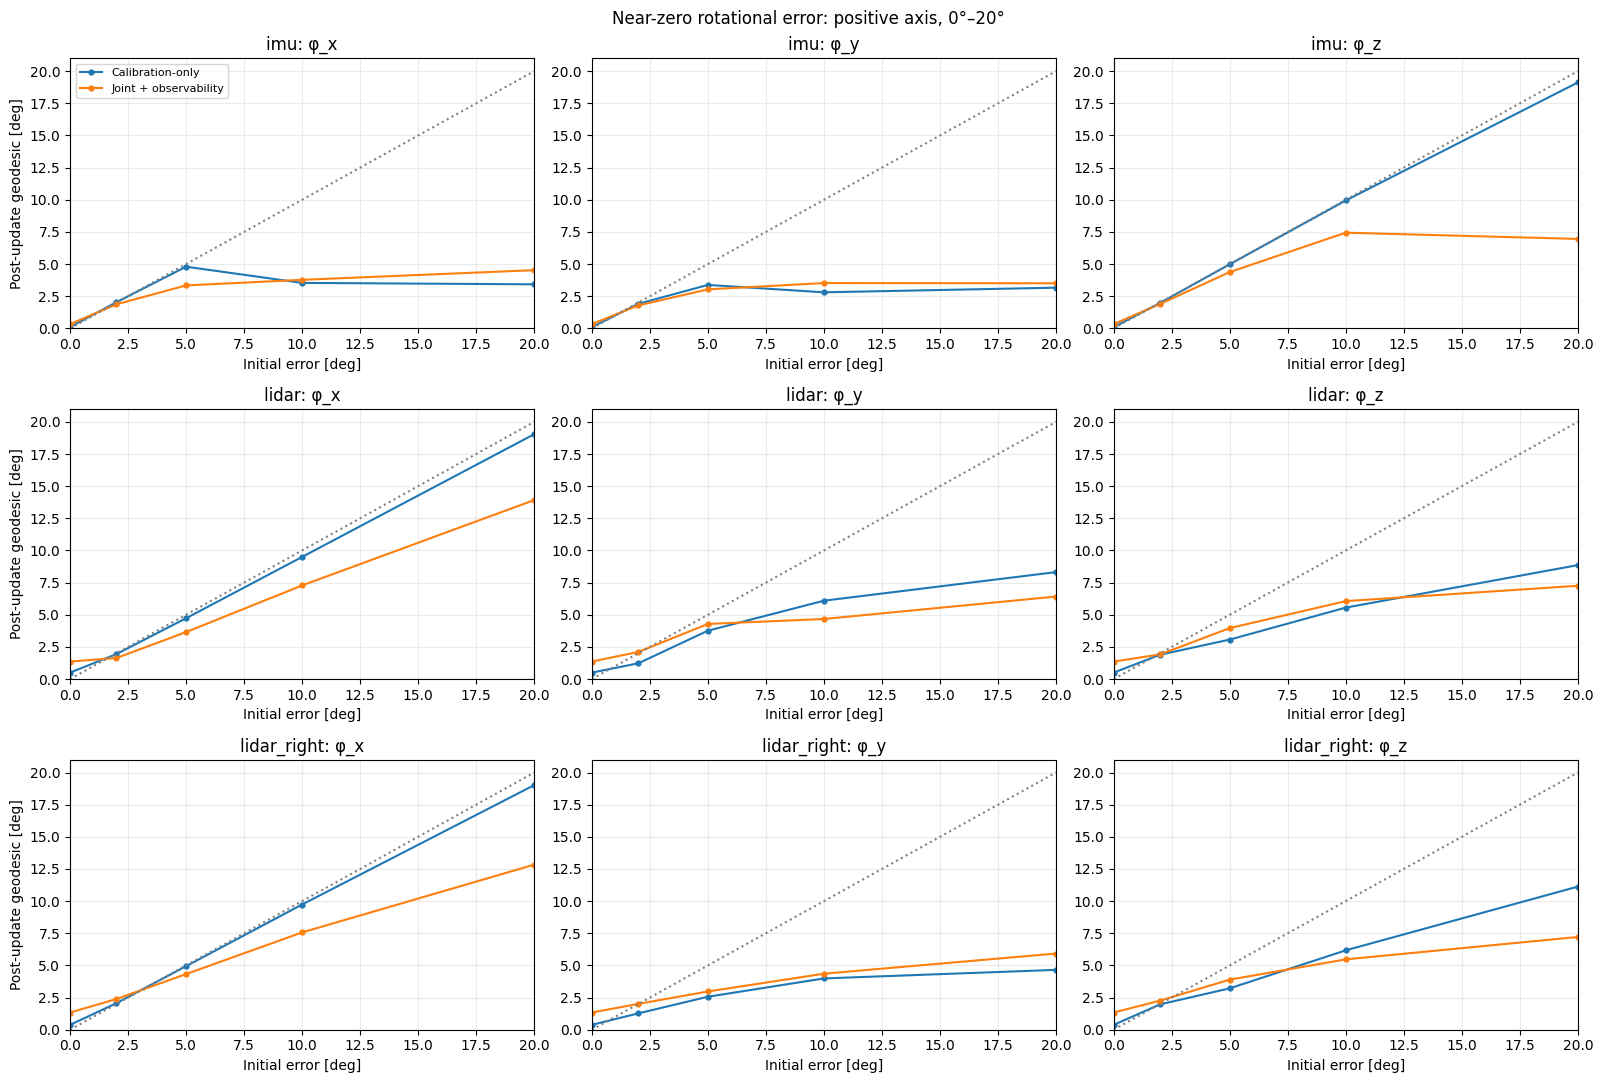

In [24]:
# Pure-axis rotational one-step curves. Always begin at 0° and retain both perturbation signs.
rotation_only = isolated_summary[isolated_summary.condition == "rotation_only"]
fig, axes = plt.subplots(3, 3, figsize=(16, 12), squeeze=False)
for row, sensor in enumerate(CALIBRATION_KEYS):
    for col, axis in enumerate("xyz"):
        ax = axes[row, col]
        group = rotation_only[(rotation_only.sensor == sensor) & (rotation_only.axis == axis)]
        for name in BACKBONES:
            model_group = group[group.model == name]
            for sign, style in ((1.0, "-o"), (-1.0, "--o")):
                branch = model_group[(model_group.initial_angle_deg * sign > 0) | (model_group.initial_angle_deg == 0)].copy()
                branch["abs_angle"] = branch.initial_angle_deg.abs()
                branch = branch.sort_values("abs_angle")
                ax.plot(branch.abs_angle, branch.after_deg, style, markersize=3.5, label=f"{name} ({'+' if sign > 0 else '−'})")
        ax.plot([0.0, max(ISOLATED_ANGLES_DEG)], [0.0, max(ISOLATED_ANGLES_DEG)], ":", color="gray", label="No correction")
        ax.set_xlim(left=0.0, right=max(ISOLATED_ANGLES_DEG))
        ax.set_ylim(bottom=0.0)
        ax.set_title(f"{sensor}: φ_{axis}")
        ax.set_xlabel("Initial absolute SO(3) error [deg]")
        ax.grid(alpha=0.25)
        if row == 0 and col == 0:
            ax.legend(fontsize=7)
    axes[row, 0].set_ylabel("Mean post-update geodesic error [deg]")
fig.suptitle("Rotation-only one-step calibration, 0° to large errors (both signs)")
fig.tight_layout()
if SAVE_RESULTS: fig.savefig(COMPARISON_OUT / "isolated_rotation_only_near_zero.png", dpi=160)
plt.show()

# A dedicated zoom makes 0–20° behavior readable despite the 130° stress cases.
fig, axes = plt.subplots(3, 3, figsize=(16, 11), squeeze=False)
for row, sensor in enumerate(CALIBRATION_KEYS):
    for col, axis in enumerate("xyz"):
        ax = axes[row, col]
        group = rotation_only[(rotation_only.sensor == sensor) & (rotation_only.axis == axis)]
        for name in BACKBONES:
            model_group = group[(group.model == name) & (group.initial_angle_deg >= 0) & (group.initial_angle_deg <= 20)]
            ax.plot(model_group.initial_angle_deg, model_group.after_deg, "-o", markersize=3.5, label=name)
        ax.plot([0, 20], [0, 20], ":", color="gray")
        ax.set_xlim(0, 20)
        ax.set_ylim(bottom=0)
        ax.set_title(f"{sensor}: φ_{axis}")
        ax.set_xlabel("Initial error [deg]")
        ax.grid(alpha=0.25)
        if row == 0 and col == 0: ax.legend(fontsize=8)
    axes[row, 0].set_ylabel("Post-update geodesic [deg]")
fig.suptitle("Near-zero rotational error: positive axis, 0°–20°")
fig.tight_layout()
if SAVE_RESULTS: fig.savefig(COMPARISON_OUT / "isolated_rotation_only_zoom_0_20.png", dpi=160)
plt.show()


### Rotation-only versus rotation+tau, and tau-only diagnostics

For the same absolute axis error, compare 0 ms with ±150 ms clock error. Do not interpret an improved one-step rotation fit as evidence that the clock itself was corrected: both rotation and tau errors are reported separately. The dedicated tau-only plot starts at zero error.

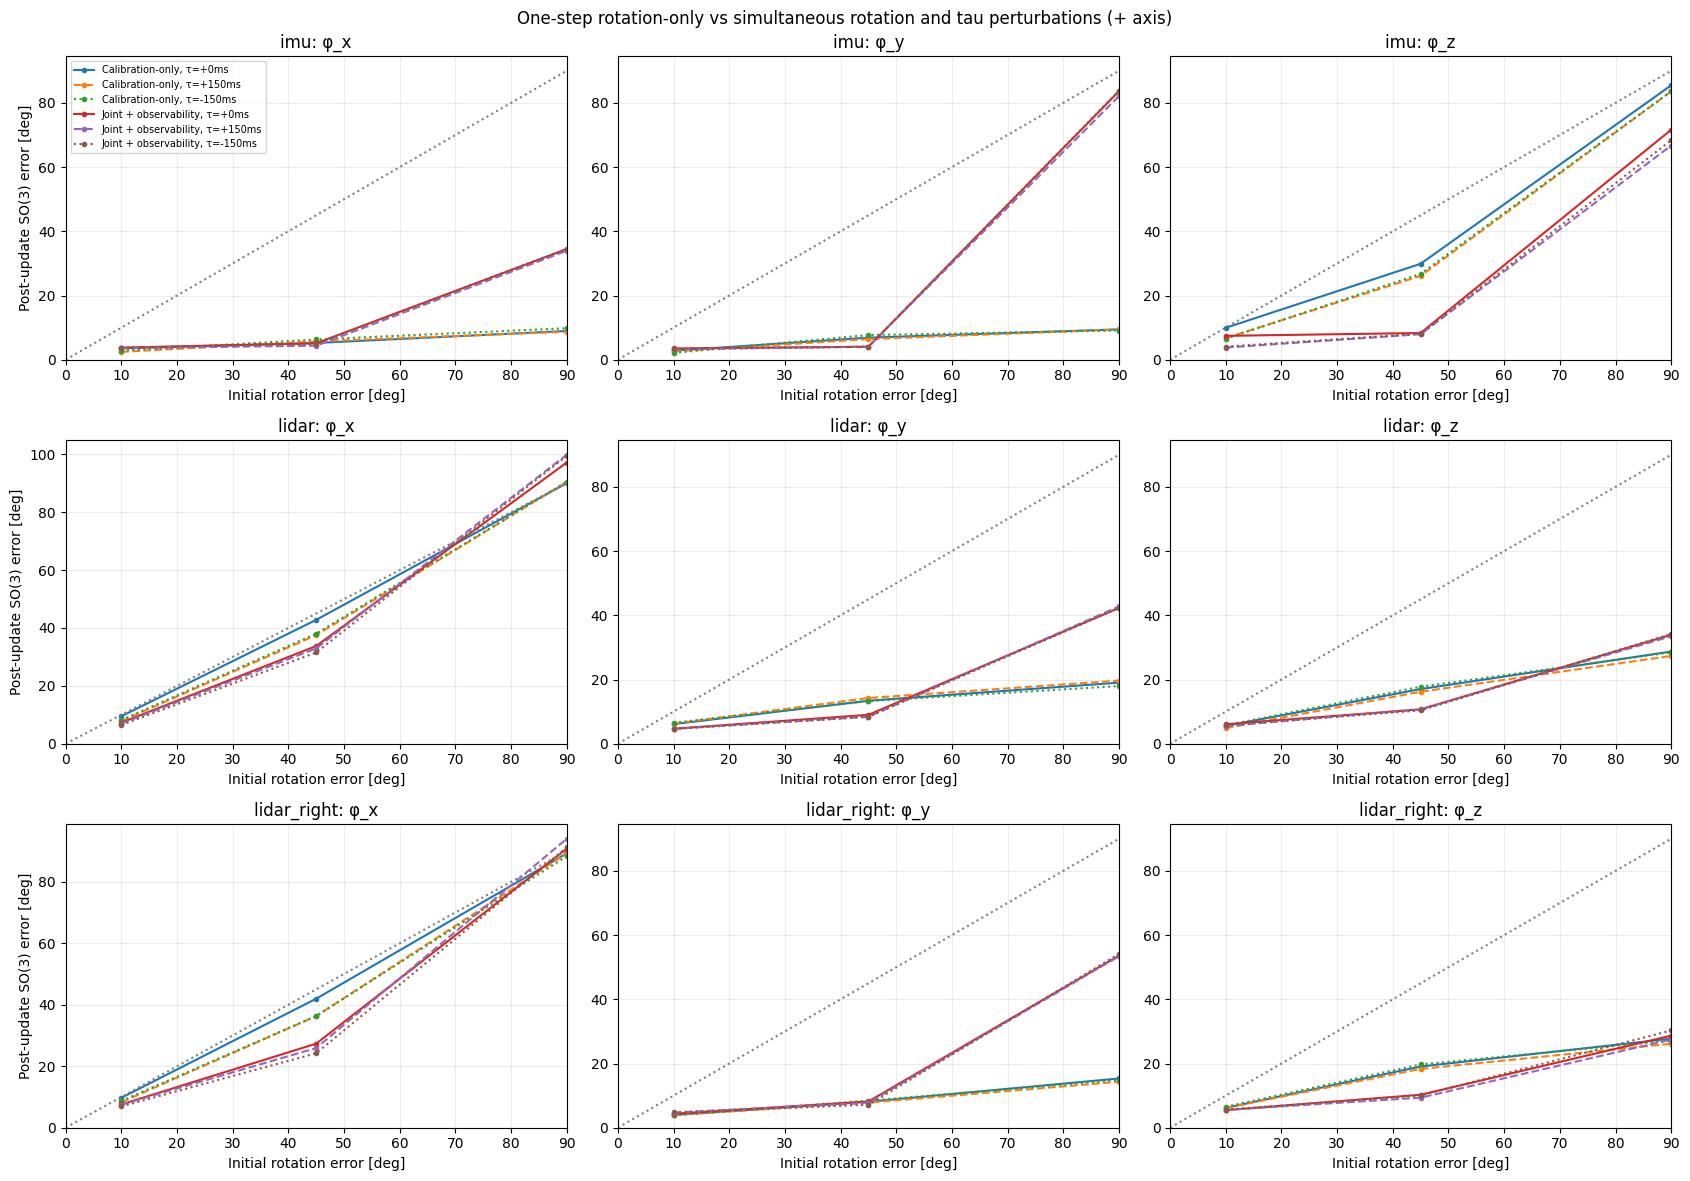

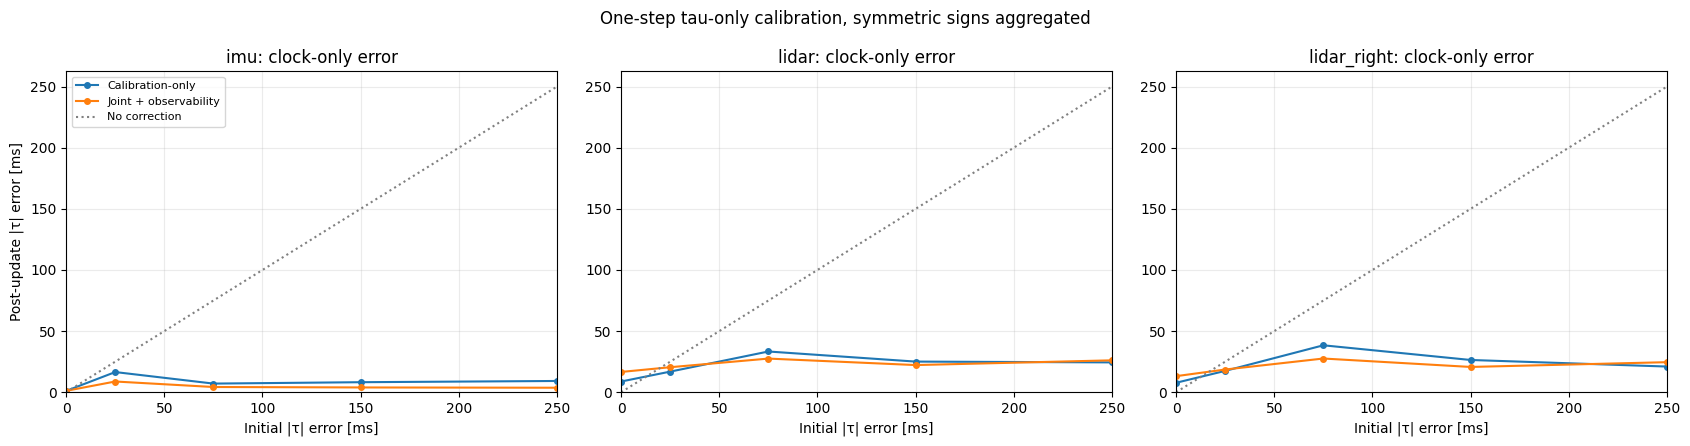

In [25]:
if RUN_COMBINED_ONE_STEP:
    fig, axes = plt.subplots(3, 3, figsize=(17, 12), squeeze=False)
    for row, sensor in enumerate(CALIBRATION_KEYS):
        for col, axis in enumerate("xyz"):
            ax = axes[row, col]
            for name in BACKBONES:
                for mode, tau, linestyle in (("rotation_only", 0.0, "-"), ("rotation_tau", 150.0, "--"), ("rotation_tau", -150.0, ":")):
                    data = isolated_summary[(isolated_summary.condition == mode) & (isolated_summary.sensor == sensor) & (isolated_summary.axis == axis) & (isolated_summary.model == name) & (isolated_summary.initial_tau_ms == tau) & (isolated_summary.initial_angle_deg > 0)]
                    data = data[data.initial_angle_deg.isin(ISOLATED_COMBINED_ANGLES_DEG)].sort_values("initial_angle_deg")
                    ax.plot(data.initial_angle_deg, data.after_deg, linestyle, marker="o", markersize=3, label=f"{name}, τ={tau:+g}ms")
            ax.plot([0, max(ISOLATED_COMBINED_ANGLES_DEG)], [0, max(ISOLATED_COMBINED_ANGLES_DEG)], color="gray", ls="dotted")
            ax.set_xlim(0, max(ISOLATED_COMBINED_ANGLES_DEG))
            ax.set_ylim(bottom=0)
            ax.set_title(f"{sensor}: φ_{axis}")
            ax.set_xlabel("Initial rotation error [deg]")
            ax.grid(alpha=.25)
            if row == 0 and col == 0: ax.legend(fontsize=7)
        axes[row, 0].set_ylabel("Post-update SO(3) error [deg]")
    fig.suptitle("One-step rotation-only vs simultaneous rotation and tau perturbations (+ axis)")
    fig.tight_layout()
    if SAVE_RESULTS: fig.savefig(COMPARISON_OUT / "isolated_rotation_tau_comparison.png", dpi=160)
    plt.show()

if RUN_TAU_ONLY_ONE_STEP:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), squeeze=False)
    for col, sensor in enumerate(CALIBRATION_KEYS):
        ax = axes[0, col]
        for name in BACKBONES:
            data = isolated_summary[(isolated_summary.condition == "tau_only") & (isolated_summary.sensor == sensor) & (isolated_summary.model == name)]
            data = data.assign(abs_tau=data.initial_tau_ms.abs()).groupby("abs_tau", as_index=False).after_tau_ms.mean().sort_values("abs_tau")
            ax.plot(data.abs_tau, data.after_tau_ms, "-o", label=name, markersize=4)
        limit = max(abs(x) for x in ISOLATED_TAU_ONLY_MS)
        ax.plot([0, limit], [0, limit], ":", color="gray", label="No correction")
        ax.set_xlim(0, limit)
        ax.set_ylim(bottom=0)
        ax.set_title(f"{sensor}: clock-only error")
        ax.set_xlabel("Initial |τ| error [ms]")
        ax.grid(alpha=.25)
        if col == 0:
            ax.set_ylabel("Post-update |τ| error [ms]")
            ax.legend(fontsize=8)
    fig.suptitle("One-step tau-only calibration, symmetric signs aggregated")
    fig.tight_layout()
    if SAVE_RESULTS: fig.savefig(COMPARISON_OUT / "isolated_tau_only.png", dpi=160)
    plt.show()


## 11. Single-sensor chronological rollouts: rotation-only, mixed rotation+tau, tau-only

For each scenario, exactly one sensor is initialized incorrectly and **only that sensor is allowed to update**. X/Y/Z rotation-only rollouts hold all clocks fixed. Mixed rollouts perturb multiple rotation axes and the clock of the same sensor. Tau-only rollouts never update rotation. All results use matched physical windows; successful convergence must persist over the last 10 windows.

The 45° rotation case is inside the prior-training magnitude bound; 90°/130° are not. Tau-only cases and the mixed cases reveal how corrections behave outside the simultaneously-perturbed training pattern. These experiments diagnose the model and a controlled update policy, **not** automatic fault detection.


In [26]:
rollout_indices = get_sequence_window_indices(test_dataset, ROLLOUT_SEQUENCE, ROLLOUT_START, ROLLOUT_NUM_WINDOWS)
rollout_windows = prepare_eval_windows(test_dataset, rollout_indices)


def run_matched_rollout(sensor_key, *, scenario, initial_rotation_vector_deg=(0.0, 0.0, 0.0), initial_tau_ms=0.0, axis="mixed"):
    """Matched chronological rollout, updating only the deliberately faulty sensor."""
    if scenario not in ("rotation_only", "mixed", "tau_only"):
        raise ValueError(scenario)
    if not rollout_windows:
        raise RuntimeError("Empty rollout sequence")
    update_rotation = scenario != "tau_only"
    update_tau = scenario != "rotation_only"
    initial_rotvec = np.asarray(initial_rotation_vector_deg, dtype=float)
    initial_degree = float(np.linalg.norm(initial_rotvec))
    reference = rollout_windows[0].current_calibration
    carry_by_model = {name: perturb_single_sensor_calibration(reference, sensor_key, rotation_vector_deg=initial_rotvec, tau_ms=initial_tau_ms) for name in BACKBONES}
    for carry in carry_by_model.values():
        assert_healthy_sensors_unchanged(reference, carry, sensor_key)

    score_id = ("xyz".index(axis) if axis in "xyz" and len(axis) == 1 else 6 if scenario == "tau_only" else None)
    rows = []
    with torch.inference_mode():
        for name, states in carry_by_model.items():
            truth = reference[sensor_key]
            rotation_error = float(so3_geodesic_deg(states[sensor_key].transform[:, :3, :3], truth.transform[:, :3, :3]).item())
            tau_error = float(1000.0 * (states[sensor_key].time_offset - truth.time_offset).abs().item())
            rows.append(dict(model=name, scenario=scenario, sensor=sensor_key, axis=axis, initial_deg=initial_degree, initial_tau_ms=float(initial_tau_ms), initial_rotvec_deg=str(tuple(initial_rotvec.tolist())), step=0, window_index=-1,
                             rotation_error_deg=rotation_error, axis_error_deg=float(rotation_error_components(states[sensor_key], truth)["xyz".index(axis)]) if axis in "xyz" and len(axis) == 1 else np.nan,
                             tau_error_ms=tau_error, predicted_step_deg=0.0, predicted_tau_step_ms=0.0, predicted_obs=np.nan, nominal_obs=np.nan, other_sensor_max_deg=0.0, other_sensor_max_tau_ms=0.0))

        for step, (index, original) in enumerate(zip(rollout_indices, rollout_windows), start=1):
            nominal_scores = test_target_cache.values[index, CALIBRATION_KEYS.index(sensor_key)]
            nominal_observability = float(nominal_scores[score_id].item()) if score_id is not None else float(nominal_scores[:3].mean().item())
            for name, backbone in BACKBONES.items():
                states = carry_by_model[name]
                hypothesis = clone_window_with_calibration(original, states)
                result = calibration_forward(hypothesis, backbone=backbone)
                prediction = result.predictions[sensor_key]
                if name == MODEL_LABELS[1]:
                    predicted_scores = joint_model.observability_head(result.shared_features)[0, CALIBRATION_KEYS.index(sensor_key)]
                    predicted_observability = float(predicted_scores[score_id].item()) if score_id is not None else float(predicted_scores[:3].mean().item())
                else:
                    predicted_observability = np.nan

                updated = apply_target_sensor_update(states, result, sensor_key, update_rotation=update_rotation, update_tau=update_tau)
                assert_healthy_sensors_unchanged(reference, updated, sensor_key)
                carry_by_model[name] = updated
                truth = original.current_calibration[sensor_key]
                rotation_error = float(so3_geodesic_deg(updated[sensor_key].transform[:, :3, :3], truth.transform[:, :3, :3]).item())
                tau_error = float(1000.0 * (updated[sensor_key].time_offset - truth.time_offset).abs().item())
                other_rotation = max(float(so3_geodesic_deg(updated[other].transform[:, :3, :3], original.current_calibration[other].transform[:, :3, :3]).item()) for other in CALIBRATION_KEYS if other != sensor_key)
                other_tau = max(float(1000.0 * (updated[other].time_offset - original.current_calibration[other].time_offset).abs().item()) for other in CALIBRATION_KEYS if other != sensor_key)
                rows.append(dict(model=name, scenario=scenario, sensor=sensor_key, axis=axis, initial_deg=initial_degree, initial_tau_ms=float(initial_tau_ms), initial_rotvec_deg=str(tuple(initial_rotvec.tolist())), step=step, window_index=int(index),
                                 rotation_error_deg=rotation_error, axis_error_deg=float(rotation_error_components(updated[sensor_key], truth)["xyz".index(axis)]) if axis in "xyz" and len(axis) == 1 else np.nan,
                                 tau_error_ms=tau_error, predicted_step_deg=float(torch.rad2deg(torch.linalg.vector_norm(prediction.delta_xi[:, :3], dim=-1)).item()), predicted_tau_step_ms=float(1000.0 * prediction.delta_tau.mean().item()),
                                 predicted_obs=predicted_observability, nominal_obs=nominal_observability, other_sensor_max_deg=other_rotation, other_sensor_max_tau_ms=other_tau))
    return pd.DataFrame(rows)


rollout_dfs = []
for sensor in CALIBRATION_KEYS:
    for axis in ROLLOUT_AXES:
        for angle in ROLLOUT_INITIAL_ANGLES_DEG:
            for sign in ROLLOUT_INITIAL_SIGNS:
                initial = np.zeros(3)
                initial[axis] = sign * angle
                print(f"Rollout rotation-only: {sensor} φ_{'xyz'[axis]} {sign * angle:+.0f}°", flush=True)
                rollout_dfs.append(run_matched_rollout(sensor, scenario="rotation_only", initial_rotation_vector_deg=initial, axis="xyz"[axis]))

    if RUN_MIXED_ROLLOUTS:
        for rotation in ROLLOUT_MULTI_ROTATION_DEG:
            for tau_ms in ROLLOUT_MULTI_TAU_MS:
                print(f"Rollout mixed: {sensor}, rotvec={rotation}, tau={tau_ms:+g} ms", flush=True)
                rollout_dfs.append(run_matched_rollout(sensor, scenario="mixed", initial_rotation_vector_deg=rotation, initial_tau_ms=tau_ms, axis="mixed"))

    if RUN_TAU_ONLY_ROLLOUTS:
        for tau_ms in ROLLOUT_TAU_ONLY_MS:
            print(f"Rollout tau-only: {sensor}, tau={tau_ms:+g} ms", flush=True)
            rollout_dfs.append(run_matched_rollout(sensor, scenario="tau_only", initial_tau_ms=tau_ms, axis="tau"))

rollout_data = pd.concat(rollout_dfs, ignore_index=True)
if SAVE_RESULTS: rollout_data.to_csv(COMPARISON_OUT / "rollouts_all_scenarios.csv", index=False)
print("Complete:", len(rollout_dfs), "scenarios ×", len(BACKBONES), "models")


Rollout rotation-only: imu φ_x +45°
Rollout rotation-only: imu φ_x +90°
Rollout rotation-only: imu φ_x +130°
Rollout rotation-only: imu φ_y +45°
Rollout rotation-only: imu φ_y +90°
Rollout rotation-only: imu φ_y +130°
Rollout rotation-only: imu φ_z +45°
Rollout rotation-only: imu φ_z +90°
Rollout rotation-only: imu φ_z +130°
Rollout mixed: imu, rotvec=(30.0, -40.0, 20.0), tau=+150 ms
Rollout mixed: imu, rotvec=(30.0, -40.0, 20.0), tau=-150 ms
Rollout mixed: imu, rotvec=(75.0, -35.0, 40.0), tau=+150 ms
Rollout mixed: imu, rotvec=(75.0, -35.0, 40.0), tau=-150 ms
Rollout tau-only: imu, tau=-150 ms
Rollout tau-only: imu, tau=+150 ms
Rollout rotation-only: lidar φ_x +45°
Rollout rotation-only: lidar φ_x +90°
Rollout rotation-only: lidar φ_x +130°
Rollout rotation-only: lidar φ_y +45°
Rollout rotation-only: lidar φ_y +90°
Rollout rotation-only: lidar φ_y +130°
Rollout rotation-only: lidar φ_z +45°
Rollout rotation-only: lidar φ_z +90°
Rollout rotation-only: lidar φ_z +130°
Rollout mixed: lid

In [27]:
# Joint convergence means both rotation and tau errors are low where they were deliberately perturbed.
rollout_rows = []
group_keys = ["model", "scenario", "sensor", "axis", "initial_deg", "initial_tau_ms", "initial_rotvec_deg"]
for group_id, group in rollout_data.groupby(group_keys, sort=False):
    group = group.sort_values("step")
    rotation = group.rotation_error_deg.to_numpy()
    tau = group.tau_error_ms.to_numpy()
    tail_count = min(CONVERGENCE_STABLE_WINDOWS, len(group) - 1)
    rot_tail = rotation[-tail_count:]
    tau_tail = tau[-tail_count:]
    scenario = group.scenario.iloc[0]
    rotation_required = scenario != "tau_only"
    tau_required = scenario != "rotation_only"
    stable = (not rotation_required or np.all(rot_tail <= CONVERGENCE_THRESHOLD_DEG)) and (not tau_required or np.all(tau_tail <= TAU_CONVERGENCE_THRESHOLD_MS))
    rollout_rows.append(dict(zip(group_keys, group_id), initial_rotation_error_deg=rotation[0], initial_tau_error_ms=tau[0], final_deg=rotation[-1], min_deg=rotation[1:].min(), median_last_deg=np.median(rot_tail), final_tau_ms=tau[-1], min_tau_ms=tau[1:].min(), median_last_tau_ms=np.median(tau_tail), stable_convergence=bool(stable),
                             other_sensor_final_deg=group.other_sensor_max_deg.iloc[-1], other_sensor_final_tau_ms=group.other_sensor_max_tau_ms.iloc[-1]))
rollout_summary = pd.DataFrame(rollout_rows).sort_values(["scenario", "sensor", "axis", "initial_deg", "initial_tau_ms", "model"])
display(rollout_summary.round(2))
print("Stable convergence fraction by scenario and model:")
display(rollout_summary.groupby(["scenario", "model"]).stable_convergence.agg(["count", "mean"]))
assert (rollout_data.other_sensor_max_deg.abs() < 1e-4).all(), "Healthy-sensor rotation changed or nominal extrinsics differ across windows."
assert (rollout_data.other_sensor_max_tau_ms.abs() < 1e-4).all(), "Healthy-sensor clock changed or nominal clocks differ across windows."
if SAVE_RESULTS: rollout_summary.to_csv(COMPARISON_OUT / "rollout_summary.csv", index=False)


,model,scenario,sensor,axis,initial_deg,initial_tau_ms,initial_rotvec_deg,initial_rotation_error_deg,initial_tau_error_ms,final_deg,min_deg,median_last_deg,final_tau_ms,min_tau_ms,median_last_tau_ms,stable_convergence,other_sensor_final_deg,other_sensor_final_tau_ms
20,Calibration-only,mixed,imu,mixed,53.85,-150.0,"(30.0, -40.0, 20.0)",53.85,150.0,9.71,9.34,9.58,13.78,1.71,11.80,False,0.0,0.0
21,Joint + observability,mixed,imu,mixed,53.85,-150.0,"(30.0, -40.0, 20.0)",53.85,150.0,2.12,1.00,2.19,6.73,1.62,6.59,True,0.0,0.0
18,Calibration-only,mixed,imu,mixed,53.85,150.0,"(30.0, -40.0, 20.0)",53.85,150.0,9.73,9.34,9.60,13.79,1.78,11.79,False,0.0,0.0
19,Joint + observability,mixed,imu,mixed,53.85,150.0,"(30.0, -40.0, 20.0)",53.85,150.0,2.12,1.00,2.19,6.73,1.42,6.59,True,0.0,0.0
24,Calibration-only,mixed,imu,mixed,91.92,-150.0,"(75.0, -35.0, 40.0)",91.92,150.0,10.23,9.80,10.05,13.68,0.11,11.34,False,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,Joint + observability,tau_only,lidar,tau,0.00,150.0,"(0.0, 0.0, 0.0)",0.00,150.0,0.00,0.00,0.00,2.46,0.37,10.66,False,0.0,0.0
86,Calibration-only,tau_only,lidar_right,tau,0.00,-150.0,"(0.0, 0.0, 0.0)",0.00,150.0,0.00,0.00,0.00,8.84,0.03,3.57,False,0.0,0.0
87,Joint + observability,tau_only,lidar_right,tau,0.00,-150.0,"(0.0, 0.0, 0.0)",0.00,150.0,0.00,0.00,0.00,4.90,0.27,8.16,False,0.0,0.0
88,Calibration-only,tau_only,lidar_right,tau,0.00,150.0,"(0.0, 0.0, 0.0)",0.00,150.0,0.00,0.00,0.00,8.84,0.03,3.57,False,0.0,0.0


Stable convergence fraction by scenario and model:


count      mean
scenario      model                                 
mixed         Calibration-only          12  0.000000
              Joint + observability     12  0.333333
rotation_only Calibration-only          27  0.629630
              Joint + observability     27  0.777778
tau_only      Calibration-only           6  0.333333
              Joint + observability      6  0.333333

## 12. Rollout plots: all axes and sensors

Each figure corresponds to a sensor. Rows X/Y/Z, columns initial-error magnitudes. The axis starts at step 0, displaying the **true injected initial error**. Dashed threshold lines mark 5° and 0°. Compare whether errors *remain* low, not just whether the first update is large.

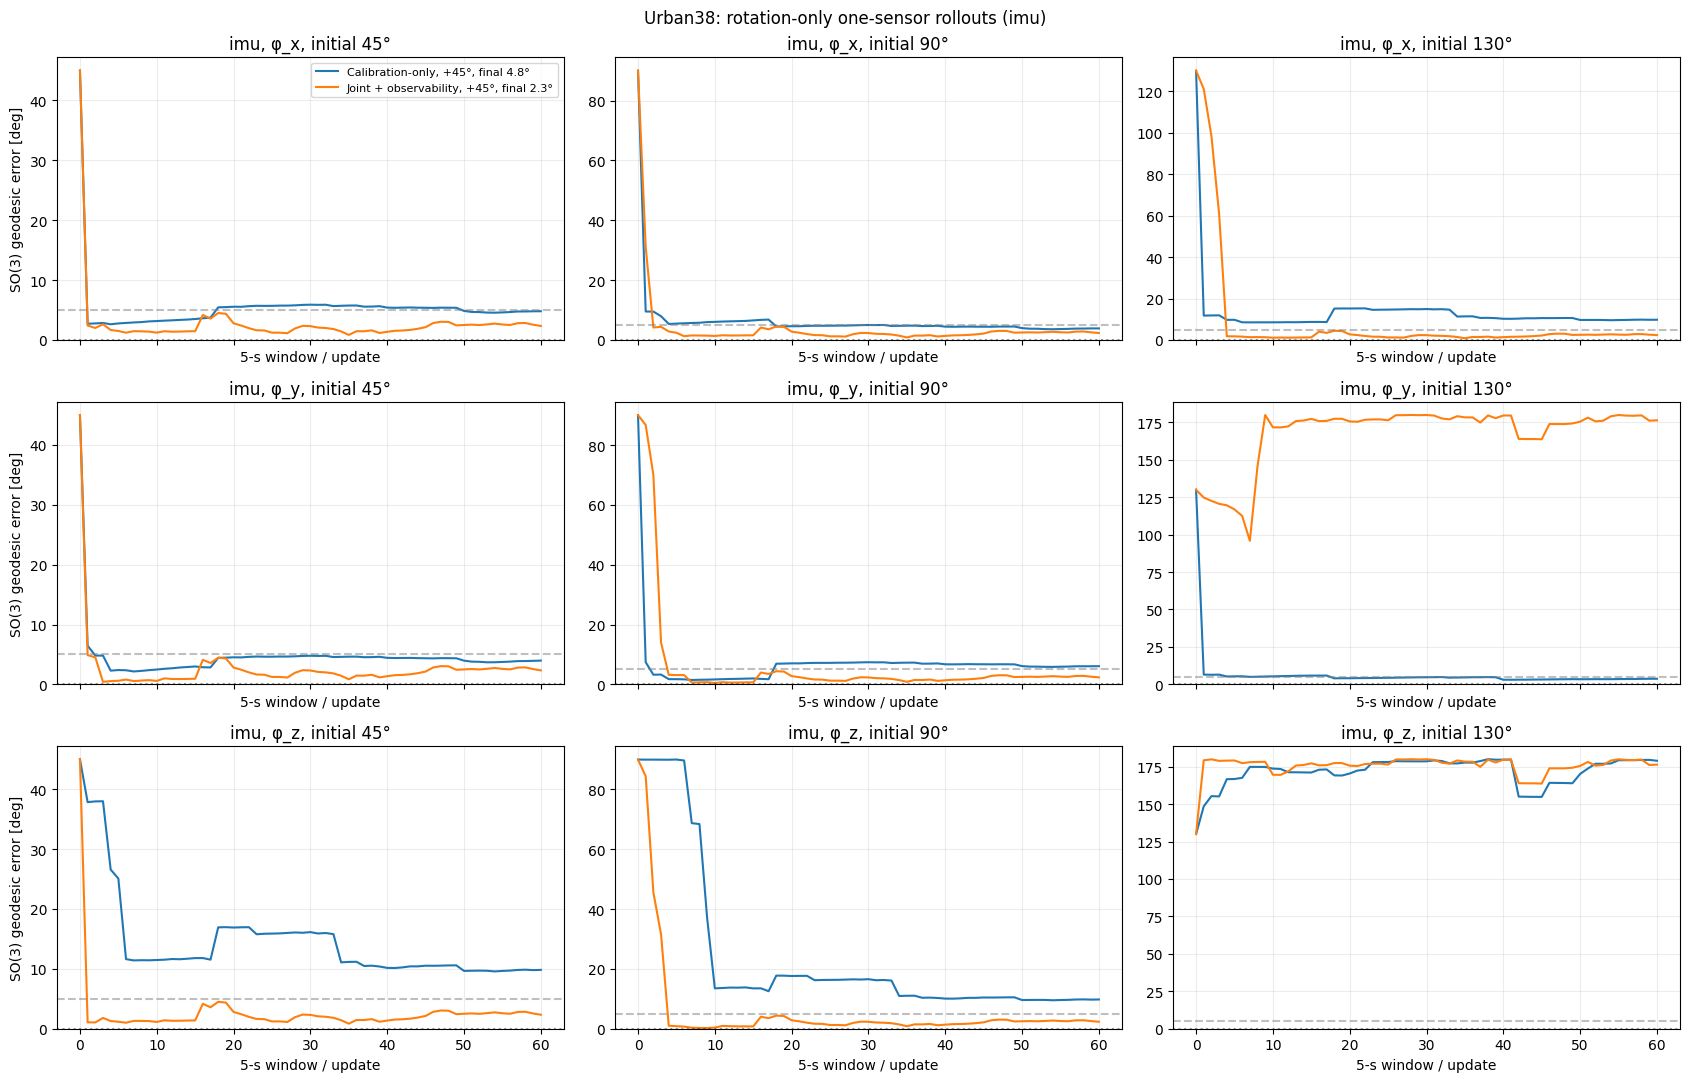

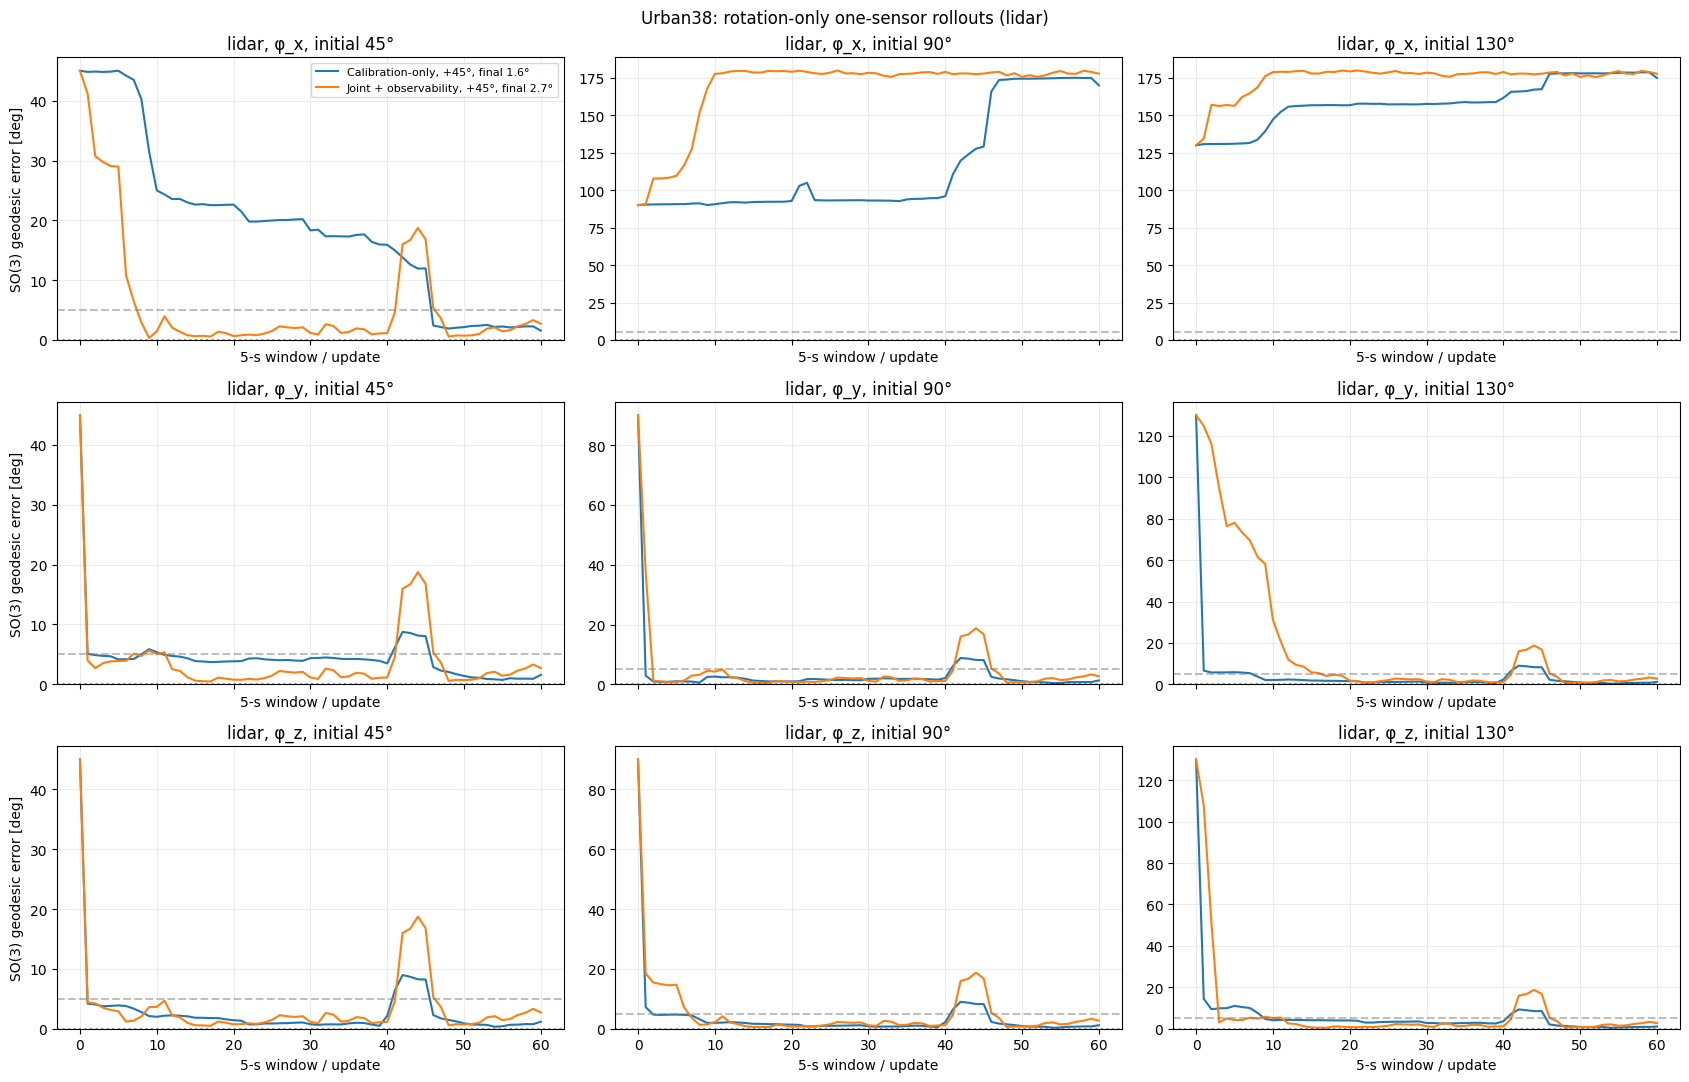

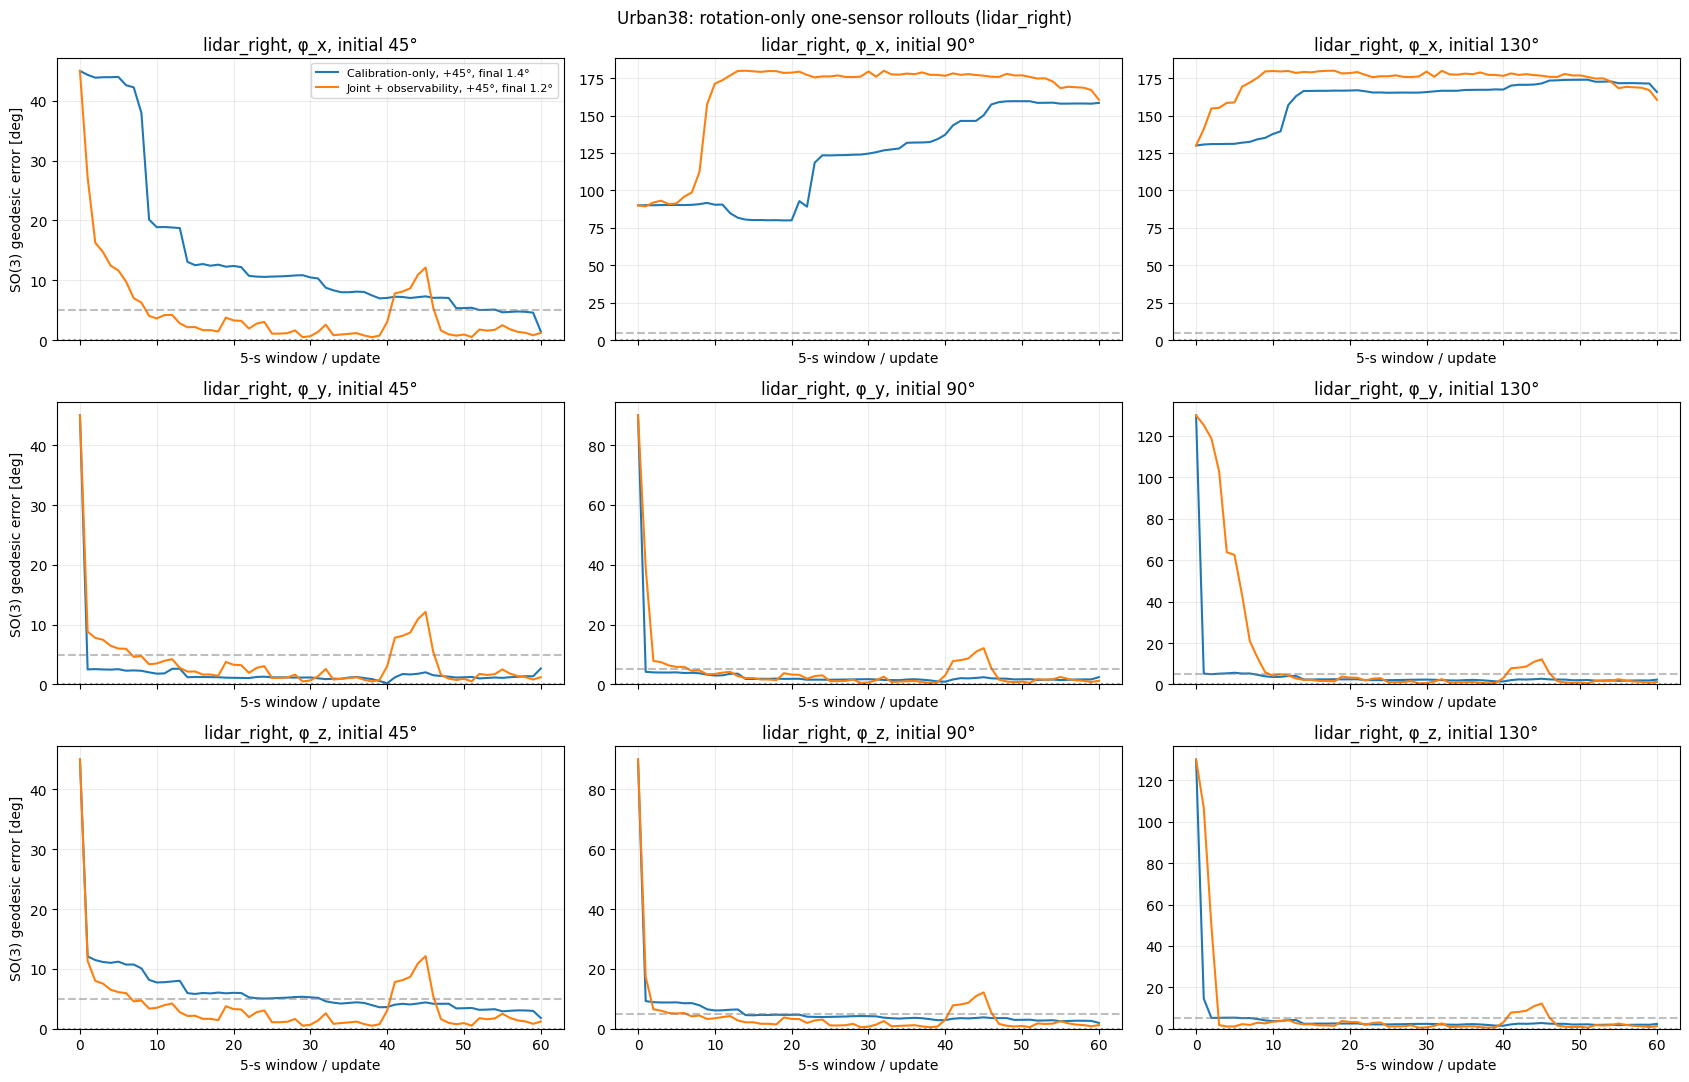

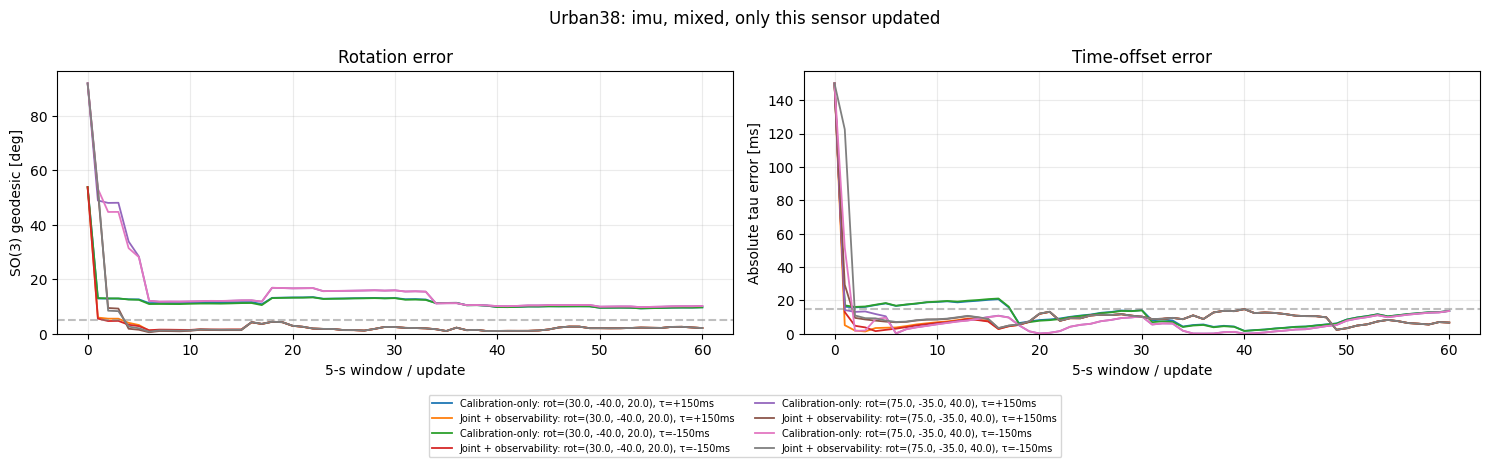

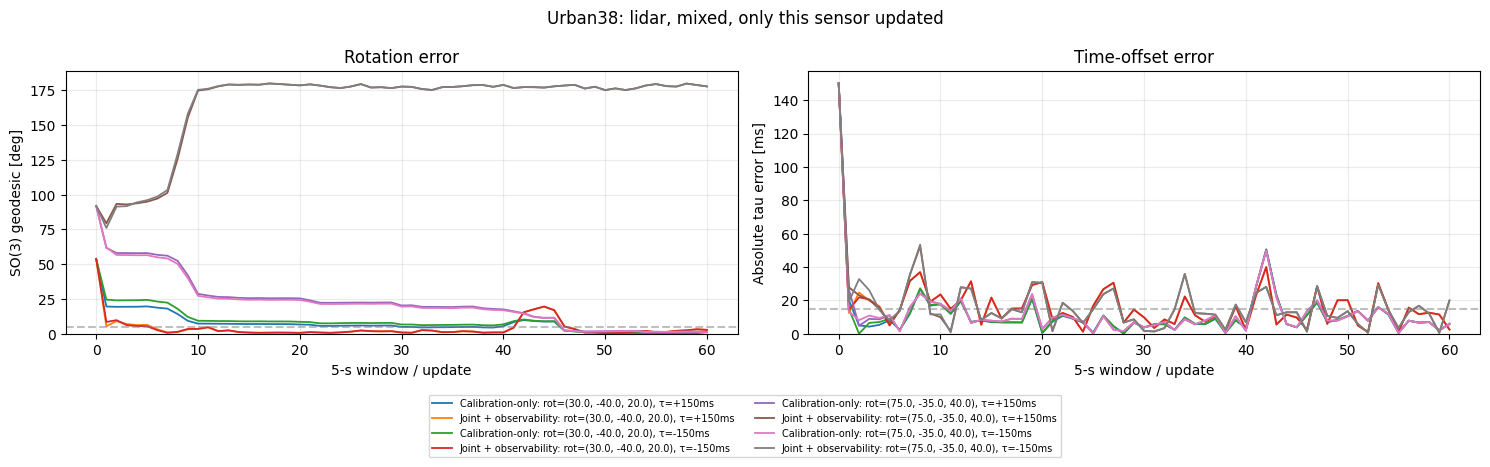

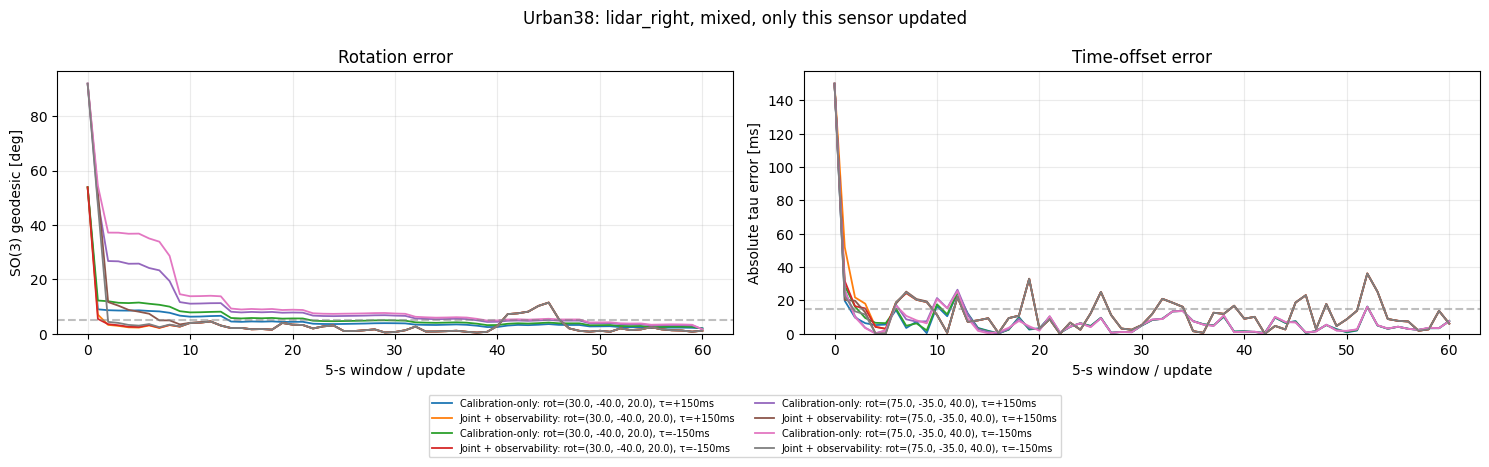

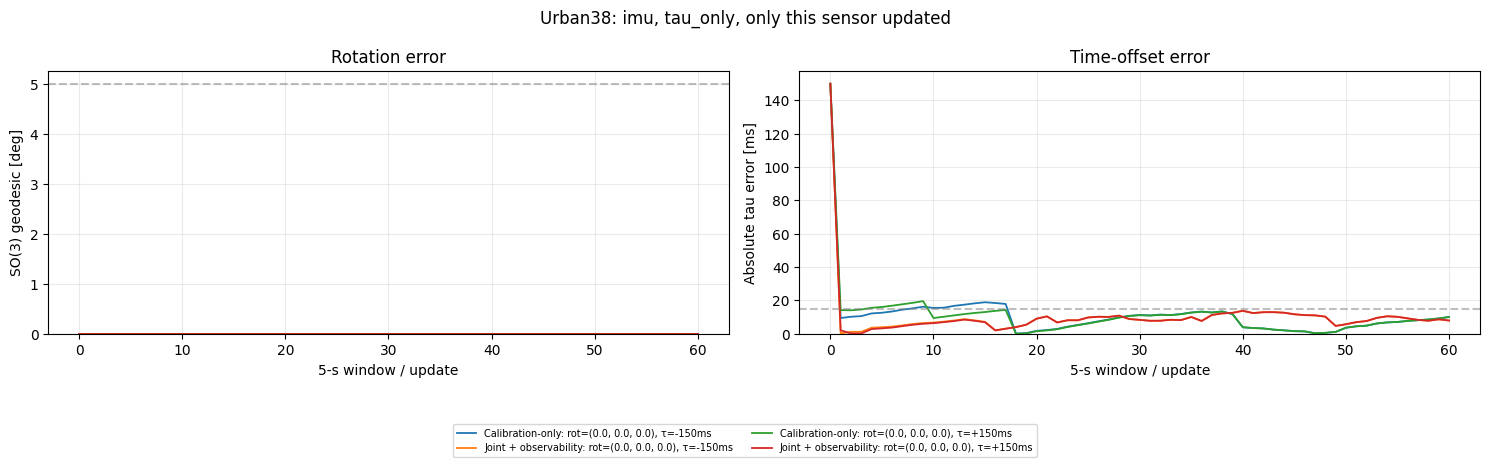

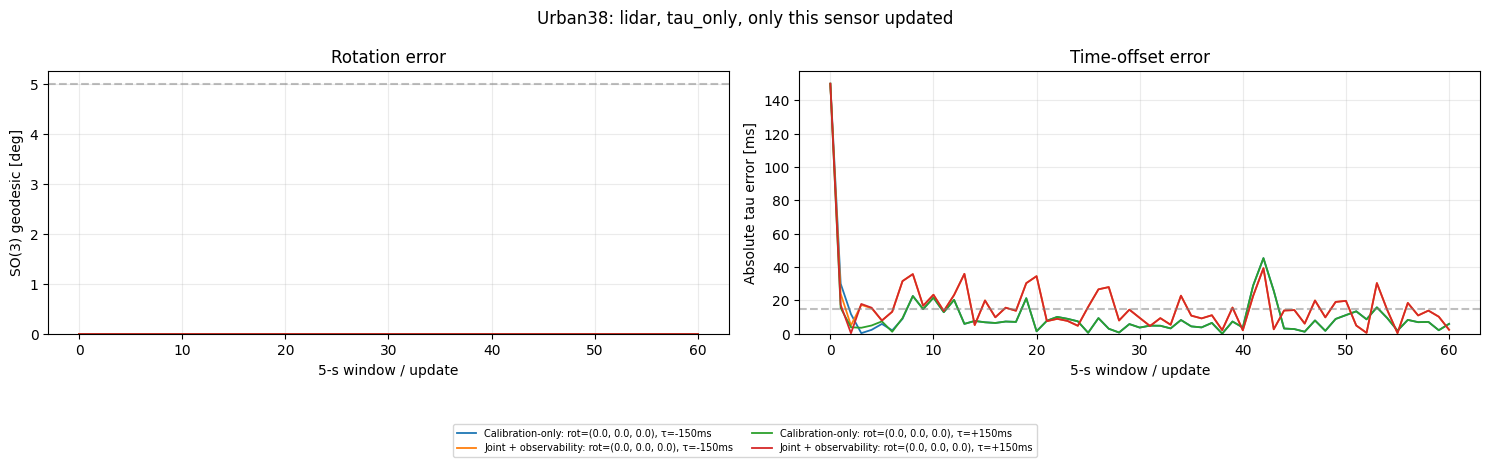

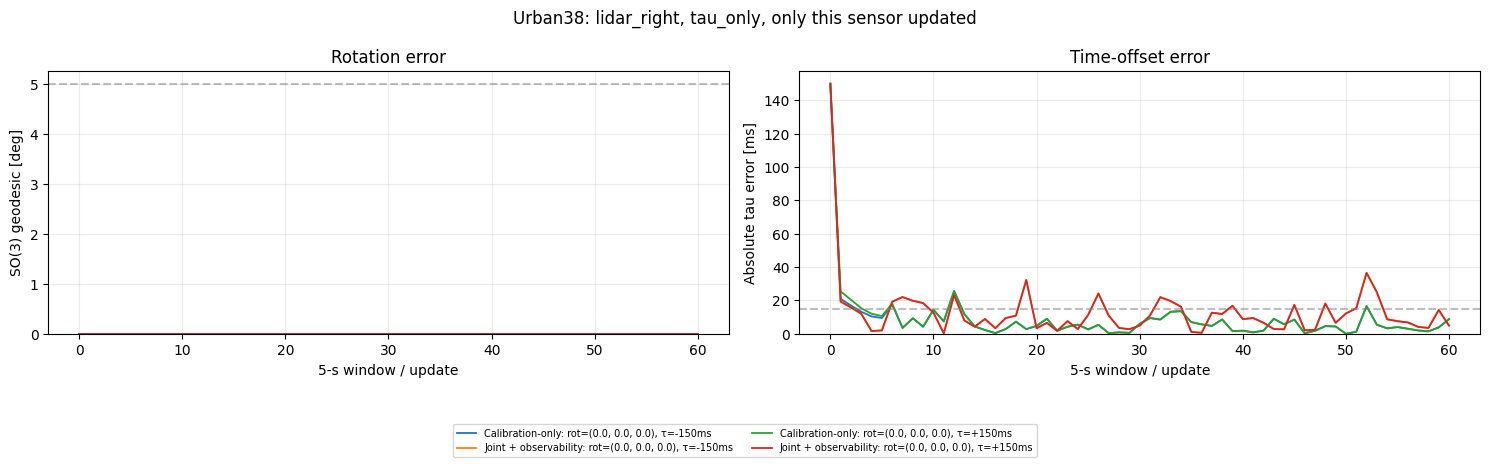

In [28]:
# Rotation-only rollout plots: other sensors and every clock are fixed.
for sensor in CALIBRATION_KEYS:
    fig, axes = plt.subplots(len(ROLLOUT_AXES), len(ROLLOUT_INITIAL_ANGLES_DEG), figsize=(17, 11), squeeze=False, sharex=True)
    for row, axis in enumerate(ROLLOUT_AXES):
        for col, angle in enumerate(ROLLOUT_INITIAL_ANGLES_DEG):
            ax = axes[row, col]
            chosen = rollout_data[(rollout_data.scenario == "rotation_only") & (rollout_data.sensor == sensor) & (rollout_data.axis == "xyz"[axis]) & (np.isclose(rollout_data.initial_deg, angle))]
            for sign in ROLLOUT_INITIAL_SIGNS:
                initial_vector = np.zeros(3)
                initial_vector[axis] = sign * angle
                matched_case = chosen[chosen.initial_rotvec_deg == str(tuple(initial_vector.tolist()))]
                for name in BACKBONES:
                    group = matched_case[matched_case.model == name].sort_values("step")
                    if group.empty:
                        continue
                    ax.plot(group.step, group.rotation_error_deg, "-" if sign > 0 else "--", label=f"{name}, {sign * angle:+g}°, final {group.rotation_error_deg.iloc[-1]:.1f}°", lw=1.5)
            ax.axhline(CONVERGENCE_THRESHOLD_DEG, ls="--", color="gray", alpha=.5)
            ax.axhline(0, ls=":", color="black", alpha=.4)
            ax.set_title(f"{sensor}, φ_{'xyz'[axis]}, initial {angle:g}°")
            ax.set_xlabel("5-s window / update")
            ax.set_ylim(bottom=0)
            ax.grid(alpha=.23)
            if row == 0 and col == 0: ax.legend(fontsize=8)
        axes[row, 0].set_ylabel("SO(3) geodesic error [deg]")
    fig.suptitle(f"{ROLLOUT_SEQUENCE}: rotation-only one-sensor rollouts ({sensor})")
    fig.tight_layout()
    if SAVE_RESULTS: fig.savefig(COMPARISON_OUT / f"rollout_rotation_only_{sensor}.png", dpi=160)
    plt.show()

# Mixed-axis+clock and tau-only rollouts are shown separately so clock convergence is visible.
for scenario in ("mixed", "tau_only"):
    if not (rollout_data.scenario == scenario).any():
        continue
    for sensor in CALIBRATION_KEYS:
        fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), squeeze=False)
        groups = rollout_data[(rollout_data.sensor == sensor) & (rollout_data.scenario == scenario)].groupby(["initial_rotvec_deg", "initial_tau_ms", "model"], sort=False)
        for (rotation, tau_ms, name), group in groups:
            group = group.sort_values("step")
            label = f"{name}: rot={rotation}, τ={tau_ms:+g}ms"
            axes[0, 0].plot(group.step, group.rotation_error_deg, label=label, lw=1.3)
            axes[0, 1].plot(group.step, group.tau_error_ms, label=label, lw=1.3)
        axes[0, 0].axhline(CONVERGENCE_THRESHOLD_DEG, ls="--", color="gray", alpha=.5)
        axes[0, 1].axhline(TAU_CONVERGENCE_THRESHOLD_MS, ls="--", color="gray", alpha=.5)
        axes[0, 0].set_title("Rotation error")
        axes[0, 1].set_title("Time-offset error")
        axes[0, 0].set_ylabel("SO(3) geodesic [deg]")
        axes[0, 1].set_ylabel("Absolute tau error [ms]")
        for ax in axes.ravel(): ax.set_xlabel("5-s window / update"); ax.set_ylim(bottom=0); ax.grid(alpha=.25)
        fig.suptitle(f"{ROLLOUT_SEQUENCE}: {sensor}, {scenario}, only this sensor updated")
        fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.025), ncol=2, fontsize=7)
        fig.tight_layout(rect=(0, .13, 1, 1))
        if SAVE_RESULTS: fig.savefig(COMPARISON_OUT / f"rollout_{scenario}_{sensor}.png", dpi=160, bbox_inches="tight")
        plt.show()


## 13. Auxiliary rollout diagnostics: prediction observability, tau and collateral updates

The observability head was trained against nominal windows; predictions on large-perturbation hypotheses need not match nominal scores. Plot this explicitly. Also inspect unintended changes of the *other two healthy sensors*, a critical deployment diagnostic.

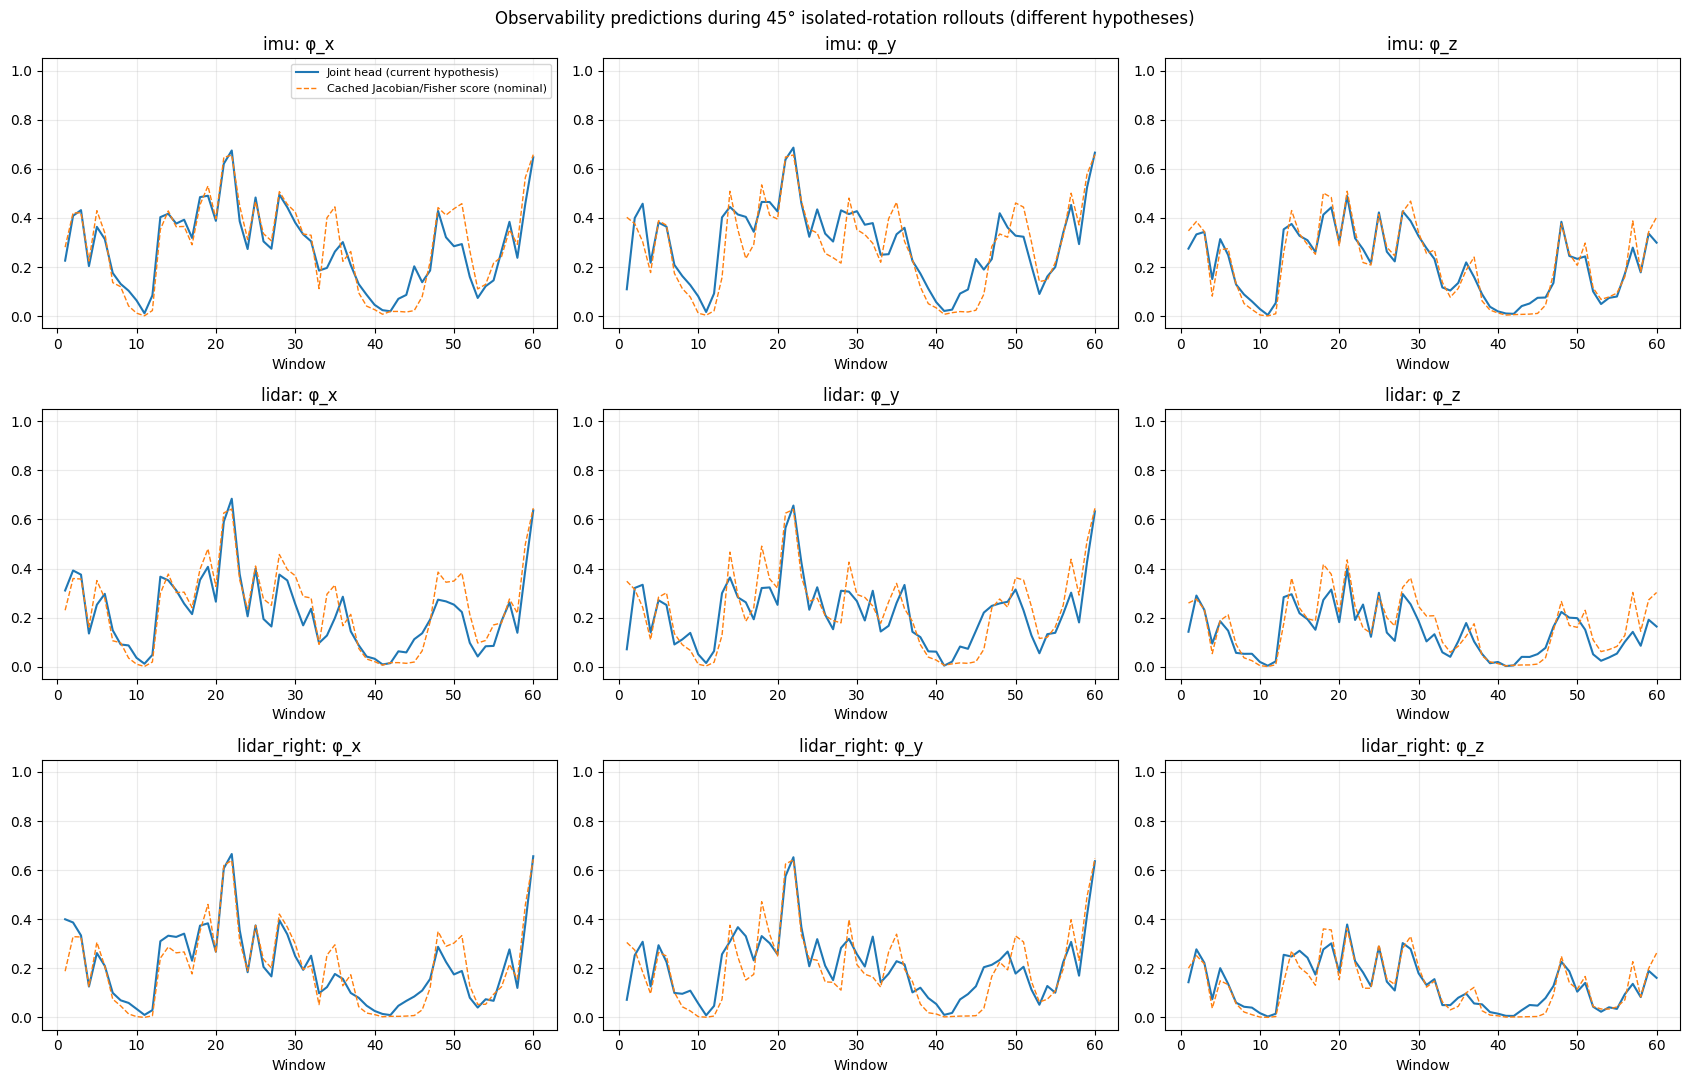

Maximum healthy-sensor SO(3) error: 0.0 deg
Maximum healthy-sensor tau error: 0.0 ms
Maximum target-sensor tau error in rotation-only rollouts: 0.0 ms


In [29]:
# Auxiliary predicted observability vs nominal Jacobian/Fisher-based score during rotation-only rollouts.
OBS_PLOT_ANGLE_DEG = 45.0 if 45.0 in ROLLOUT_INITIAL_ANGLES_DEG else ROLLOUT_INITIAL_ANGLES_DEG[0]
fig, axes = plt.subplots(3, 3, figsize=(17, 11), squeeze=False)
for row, sensor in enumerate(CALIBRATION_KEYS):
    for col, axis in enumerate("xyz"):
        ax = axes[row, col]
        probe_rotvec = np.zeros(3)
        probe_rotvec[col] = ROLLOUT_INITIAL_SIGNS[0] * OBS_PLOT_ANGLE_DEG
        group = rollout_data[(rollout_data.scenario == "rotation_only") & (rollout_data.model == MODEL_LABELS[1]) & (rollout_data.sensor == sensor) & (rollout_data.axis == axis) & (rollout_data.initial_rotvec_deg == str(tuple(probe_rotvec.tolist()))) & (rollout_data.step > 0)].sort_values("step")
        ax.plot(group.step, group.predicted_obs, lw=1.5, label="Joint head (current hypothesis)")
        ax.plot(group.step, group.nominal_obs, ls="--", lw=1.0, label="Cached Jacobian/Fisher score (nominal)")
        ax.set_ylim(-.05, 1.05)
        ax.set_title(f"{sensor}: φ_{axis}")
        ax.set_xlabel("Window")
        ax.grid(alpha=.25)
        if row == 0 and col == 0: ax.legend(fontsize=8)
fig.suptitle(f"Observability predictions during {OBS_PLOT_ANGLE_DEG:g}° isolated-rotation rollouts (different hypotheses)")
fig.tight_layout()
plt.show()

# Healthy-sensor updates should be exactly zero; target-sensor tau remains fixed in rotation-only cases.
rotation_only_rollouts = rollout_data[rollout_data.scenario == "rotation_only"]
print("Maximum healthy-sensor SO(3) error:", rotation_only_rollouts.other_sensor_max_deg.max(), "deg")
print("Maximum healthy-sensor tau error:", rotation_only_rollouts.other_sensor_max_tau_ms.max(), "ms")
print("Maximum target-sensor tau error in rotation-only rollouts:", rotation_only_rollouts.tau_error_ms.max(), "ms")


## 14. Interpretation and next experiment

- The observability targets come from **a manually constructed measurement Jacobian and its Fisher information matrix**, mapped to dimensionless coordinate scores. No factor graph optimizer is used to obtain them.
- A high correlation from the paired Student-t test need not transfer to pure-axis rotations with a correct clock. Compare the rotation-only and rotation+tau one-step plots **at the same angle and physical windows**.
- The default rollouts **isolate a single sensor**: neither of the other two sensor calibrations changes. Rotation-only rollouts freeze every clock. Mixed rollouts test multi-axis rotation plus tau for **that same sensor**, and tau-only rollouts test just one clock.
- At 45° the axis-aligned error lies within the 60° training magnitude limit, though the direction and missing tau perturbation can still be distribution shifts. 90° and 130° are outside the trained rotation range.
- A model predicting accurate observability scores does not automatically use them to gate calibration updates; the two heads share representations but the correction head remains independent.
- **Do not fine-tune only rotation or only tau exclusively.** If diagnostics establish a distribution mismatch, consider a training mixture of rotation-only, tau-only, and combined perturbations, including some pure-axis rotations. Keep the current paired loss unchanged and first compare it against the correction-only control with matched fine-tuning.
- For future `002.16` versus new joint checkpoints, change the two checkpoint paths in Section 2. Results save under `runs/<RUN_NAME>/`.


LiDAR X: raw correction versus oracle X-only update (both signs, same windows)


,sensor,model,initial_abs_deg,N,x_correction_MAE,other_axes_deg,after_full_deg,after_x_only_deg,improve_full
0,lidar,Calibration-only,10.0,24,9.579,0.426,9.602,9.579,0.750
1,lidar,Calibration-only,30.0,24,28.385,0.603,28.400,28.385,0.875
2,lidar,Calibration-only,45.0,24,42.273,0.776,42.292,42.273,0.917
3,lidar,Calibration-only,90.0,24,90.334,0.911,90.342,90.334,0.333
4,lidar,Calibration-only,130.0,24,132.702,0.841,132.705,132.702,0.042
5,lidar,Joint + observability,10.0,24,7.792,0.817,7.909,7.792,0.875
6,lidar,Joint + observability,30.0,24,21.059,1.540,21.269,21.059,0.917
7,lidar,Joint + observability,45.0,24,32.231,2.031,32.506,32.231,0.917
8,lidar,Joint + observability,90.0,24,91.599,1.951,91.658,91.599,0.208
9,lidar,Joint + observability,130.0,24,143.820,2.343,143.850,143.820,0.042


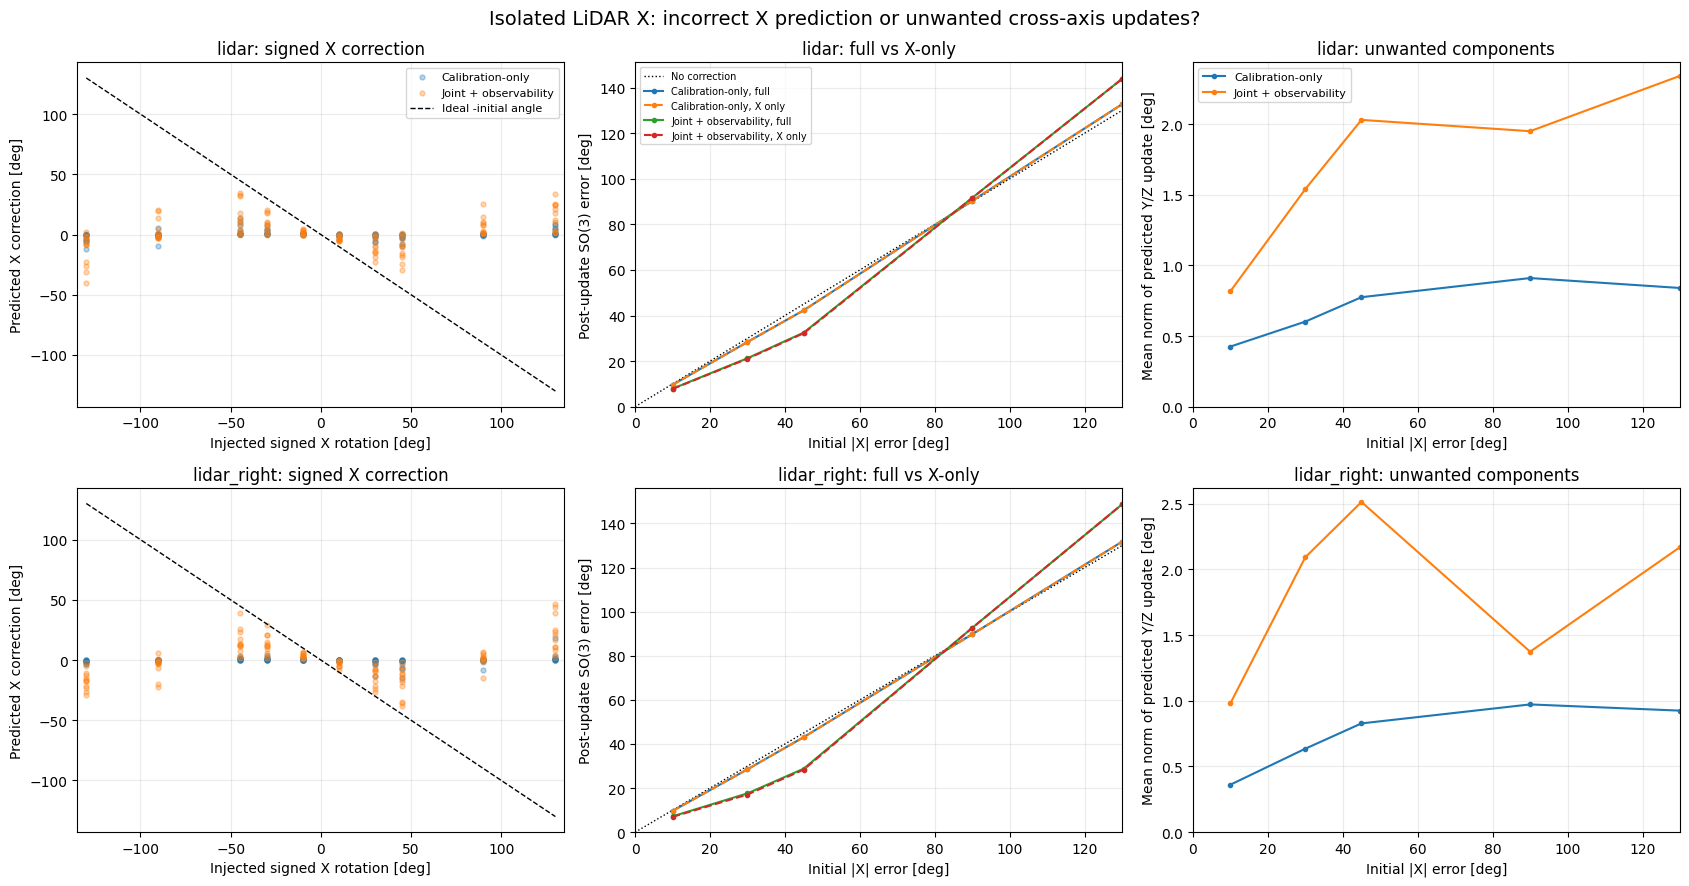

In [30]:
# %% Cell 1: Signed rotation correction versus full-vector and axis-only SO(3) updates.
# Append after notebook 32's existing inference and rollout cells.

DIAG1_SENSORS = ("lidar", "lidar_right")
DIAG1_ANGLES_DEG = (10.0, 30.0, 45.0, 90.0, 130.0)
DIAG1_WINDOWS = 12  # First 12 Urban38 windows, matching the earlier isolated-angle experiment.
DIAG_BATCH_SIZE = 8

@torch.inference_mode()
def collect_axis_diagnostics(indices, *, sensors, axes, angles_deg, batch_size=8):
    '''Compare the raw complete rotation update against an oracle axis-only update.'''
    rows = []
    indices = [int(index) for index in indices]
    if not indices:
        raise ValueError("No evaluation windows selected.")

    for sensor in sensors:
        sensor_id = CALIBRATION_KEYS.index(sensor)
        for axis in axes:
            off_axis_indices = [component for component in range(3) if component != axis]
            for magnitude in angles_deg:
                for sign in ((1.0,) if magnitude == 0 else (1.0, -1.0)):
                    signed_angle = float(sign * magnitude)
                    rotation_vector = np.zeros(3, dtype=float)
                    rotation_vector[axis] = signed_angle

                    for start in range(0, len(indices), batch_size):
                        batch_indices = indices[start:start + batch_size]
                        base = collate_windows([test_dataset[index] for index in batch_indices])
                        base = window_batch_to(base, DEVICE, dtype=MODEL_DTYPE)
                        true_states = base.current_calibration
                        wrong_states = perturb_single_sensor_calibration(true_states, sensor, rotation_vector_deg=rotation_vector, tau_ms=0.0)
                        hypothesis = clone_window_with_calibration(base, wrong_states)
                        results, joint_scores = inference_both(hypothesis)

                        R_true = true_states[sensor].transform[:, :3, :3]
                        R_wrong = wrong_states[sensor].transform[:, :3, :3]
                        before_deg = so3_geodesic_deg(R_wrong, R_true)
                        if not torch.allclose(before_deg, torch.full_like(before_deg, abs(signed_angle)), atol=0.05, rtol=0):
                            raise AssertionError("Unexpected initial SO(3) error; check perturbation convention.")

                        reference_scores = test_target_cache.values[torch.as_tensor(batch_indices, dtype=torch.long), sensor_id, axis].detach().cpu().numpy()
                        joint_scores_numpy = joint_scores[:, sensor_id, axis].detach().cpu().numpy()

                        for name, output in results.items():
                            delta_r = output.predictions[sensor].delta_xi[:, :3]
                            delta_axis = torch.zeros_like(delta_r)
                            delta_axis[:, axis] = delta_r[:, axis]

                            R_after_full = so3_exp(delta_r) @ R_wrong
                            R_after_axis = so3_exp(delta_axis) @ R_wrong
                            error_full = so3_geodesic_deg(R_after_full, R_true).detach().cpu().numpy()
                            error_axis = so3_geodesic_deg(R_after_axis, R_true).detach().cpu().numpy()
                            pred_axis_deg = torch.rad2deg(delta_r[:, axis]).detach().cpu().numpy()
                            unintended_deg = torch.rad2deg(torch.linalg.vector_norm(delta_r[:, off_axis_indices], dim=-1)).detach().cpu().numpy()
                            initial_errors = before_deg.detach().cpu().numpy()

                            for j, index in enumerate(batch_indices):
                                rows.append(dict(
                                    model=name, sensor=sensor, axis="xyz"[axis], window_index=index,
                                    sequence=test_dataset.sequence_name_for_window(index),
                                    initial_signed_deg=signed_angle, initial_abs_deg=abs(signed_angle),
                                    ideal_axis_update_deg=-signed_angle, predicted_axis_update_deg=float(pred_axis_deg[j]),
                                    axis_update_mae_deg=abs(float(pred_axis_deg[j]) + signed_angle),
                                    unintended_other_axes_deg=float(unintended_deg[j]),
                                    before_deg=float(initial_errors[j]), after_full_deg=float(error_full[j]),
                                    after_axis_only_deg=float(error_axis[j]),
                                    improved_full=bool(error_full[j] < initial_errors[j] - 1e-6),
                                    improved_axis_only=bool(error_axis[j] < initial_errors[j] - 1e-6),
                                    nominal_observability=float(reference_scores[j]),
                                    predicted_observability=float(joint_scores_numpy[j]) if name == MODEL_LABELS[1] else np.nan,
                                ))
    return pd.DataFrame.from_records(rows)


diag1_indices = get_sequence_window_indices(test_dataset, "Urban38", 0, DIAG1_WINDOWS)
diag1 = collect_axis_diagnostics(diag1_indices, sensors=DIAG1_SENSORS, axes=(0,), angles_deg=DIAG1_ANGLES_DEG, batch_size=DIAG_BATCH_SIZE)

diag1_summary = diag1.groupby(["sensor", "model", "initial_abs_deg"], as_index=False).agg(
    N=("window_index", "count"), x_correction_MAE=("axis_update_mae_deg", "mean"),
    other_axes_deg=("unintended_other_axes_deg", "mean"), after_full_deg=("after_full_deg", "mean"),
    after_x_only_deg=("after_axis_only_deg", "mean"), improve_full=("improved_full", "mean"),
)
print("LiDAR X: raw correction versus oracle X-only update (both signs, same windows)")
display(diag1_summary.round(3))

fig, axes = plt.subplots(len(DIAG1_SENSORS), 3, figsize=(17, 9), squeeze=False)
for row, sensor in enumerate(DIAG1_SENSORS):
    data = diag1[diag1.sensor == sensor]
    ax = axes[row, 0]
    for name in BACKBONES:
        subset = data[data.model == name]
        ax.scatter(subset.initial_signed_deg, subset.predicted_axis_update_deg, s=13, alpha=0.32, label=name)
    limit = max(DIAG1_ANGLES_DEG)
    ax.plot([-limit, limit], [limit, -limit], "k--", linewidth=1, label="Ideal -initial angle")
    ax.set(xlim=(-limit - 5, limit + 5), xlabel="Injected signed X rotation [deg]", ylabel="Predicted X correction [deg]", title=f"{sensor}: signed X correction")
    ax.grid(alpha=0.25)
    if row == 0: ax.legend(fontsize=8)

    ax = axes[row, 1]
    ax.plot([0, limit], [0, limit], "k:", linewidth=1, label="No correction")
    for name in BACKBONES:
        subset = diag1_summary[(diag1_summary.sensor == sensor) & (diag1_summary.model == name)].sort_values("initial_abs_deg")
        ax.plot(subset.initial_abs_deg, subset.after_full_deg, "-o", markersize=3, label=f"{name}, full")
        ax.plot(subset.initial_abs_deg, subset.after_x_only_deg, "--o", markersize=3, label=f"{name}, X only")
    ax.set(xlim=(0, limit), ylim=(0, None), xlabel="Initial |X| error [deg]", ylabel="Post-update SO(3) error [deg]", title=f"{sensor}: full vs X-only")
    ax.grid(alpha=0.25)
    if row == 0: ax.legend(fontsize=7)

    ax = axes[row, 2]
    for name in BACKBONES:
        subset = diag1_summary[(diag1_summary.sensor == sensor) & (diag1_summary.model == name)].sort_values("initial_abs_deg")
        ax.plot(subset.initial_abs_deg, subset.other_axes_deg, "-o", markersize=3, label=name)
    ax.set(xlim=(0, limit), ylim=(0, None), xlabel="Initial |X| error [deg]", ylabel="Mean norm of predicted Y/Z update [deg]", title=f"{sensor}: unwanted components")
    ax.grid(alpha=0.25)
    if row == 0: ax.legend(fontsize=8)
fig.suptitle("Isolated LiDAR X: incorrect X prediction or unwanted cross-axis updates?", fontsize=14)
fig.tight_layout()
plt.show()

if SAVE_RESULTS:
    diag1.to_csv(COMPARISON_OUT / "isolated_x_signed_and_cross_axis.csv", index=False)
    diag1_summary.to_csv(COMPARISON_OUT / "isolated_x_signed_and_cross_axis_summary.csv", index=False)


Urban38: selected 64/349 windows
Urban39: selected 64/350 windows
Observability-conditioned one-step results (N counts both +/- signs; 'windows' counts distinct physical windows)


,sensor,axis,initial_abs_deg,model,obs_bin,N,windows,score_mean,gain_full,gain_axis_only,improve_full,after_full_deg,after_axis_only_deg,x_correction_MAE,other_axes_deg
0,lidar,x,10.0,Calibration-only,"(-0.001, 0.2]",76,38,0.080,0.031,0.049,0.711,9.691,9.513,9.513,0.776
1,lidar,x,10.0,Calibration-only,"(0.2, 0.4]",98,49,0.299,0.007,0.008,0.663,9.926,9.924,9.924,0.146
2,lidar,x,10.0,Calibration-only,"(0.4, 0.6]",62,31,0.484,0.012,0.012,0.565,9.881,9.879,9.879,0.135
3,lidar,x,10.0,Calibration-only,"(0.6, 0.8]",20,10,0.633,0.066,0.075,0.900,9.340,9.249,9.249,0.714
4,lidar,x,10.0,Joint + observability,"(-0.001, 0.2]",76,38,0.080,0.155,0.251,0.803,8.450,7.493,7.493,2.190
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,lidar_right,x,130.0,Calibration-only,"(0.6, 0.8]",18,9,0.633,-0.088,-0.087,0.000,141.412,141.275,141.275,6.804
76,lidar_right,x,130.0,Joint + observability,"(-0.001, 0.2]",92,46,0.083,-0.110,-0.110,0.033,144.332,144.273,144.421,3.731
77,lidar_right,x,130.0,Joint + observability,"(0.2, 0.4]",94,47,0.292,-0.054,-0.054,0.064,136.985,136.981,136.981,1.013
78,lidar_right,x,130.0,Joint + observability,"(0.4, 0.6]",52,26,0.489,-0.063,-0.063,0.058,138.255,138.241,138.241,1.601


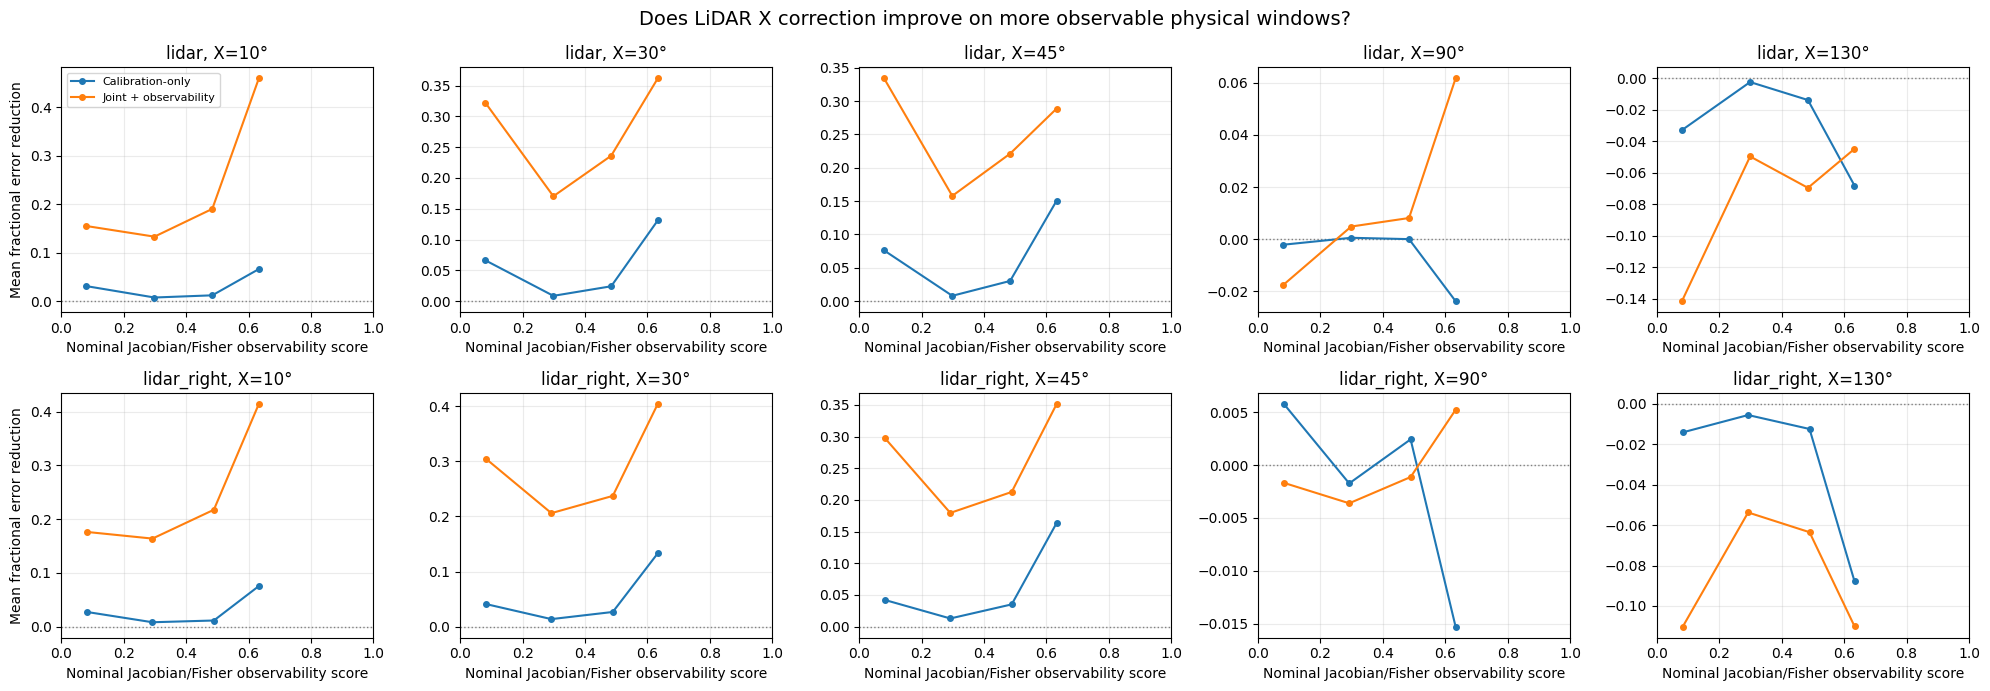

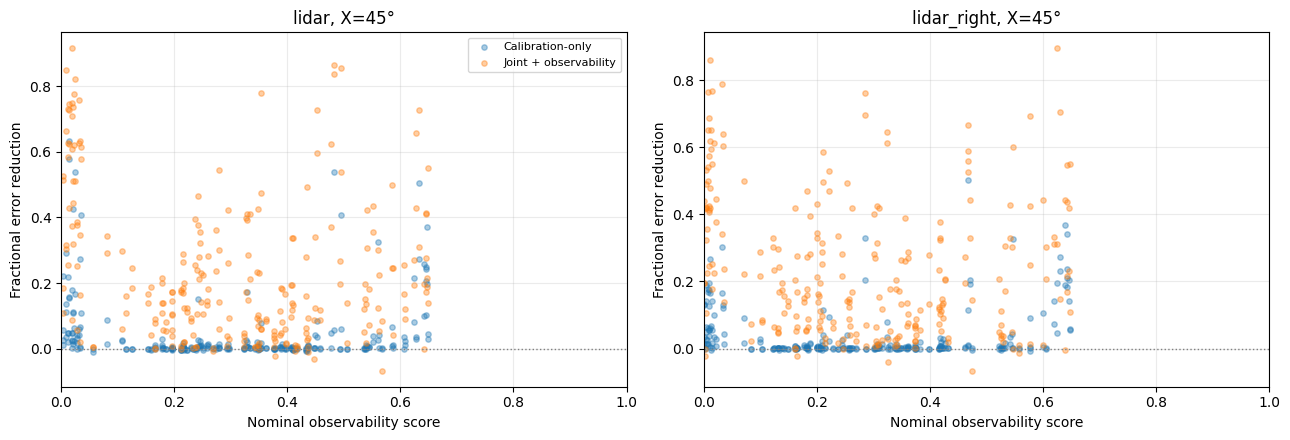

In [31]:
# %% Cell 2: Wider held-out evaluation, stratified by nominal Jacobian/Fisher observability.
# The cached score belongs to the original, unperturbed physical window. It is NOT recomputed at a wrong calibration.

DIAG2_SEQUENCES = ("Urban38", "Urban39")
DIAG2_WINDOWS_PER_SEQUENCE = 64
DIAG2_SENSORS = ("lidar", "lidar_right")
DIAG2_AXES = (0,)  # Start with LiDAR X; change to (0, 1, 2) for the full per-axis comparison.
DIAG2_ANGLES_DEG = (10.0, 30.0, 45.0, 90.0, 130.0)
DIAG2_SCORE_BINS = (0.0, 0.2, 0.4, 0.6, 0.8, 1.0)


def evenly_spaced_sequence_indices(dataset, sequences, per_sequence):
    selected = []
    for sequence in sequences:
        indices = list(dataset.window_indices_for_sequence(sequence))
        count = min(per_sequence, len(indices))
        positions = np.unique(np.linspace(0, len(indices) - 1, count, dtype=int))
        selected.extend(int(indices[position]) for position in positions)
        print(f"{sequence}: selected {len(positions)}/{len(indices)} windows")
    return selected


diag2_indices = evenly_spaced_sequence_indices(test_dataset, DIAG2_SEQUENCES, DIAG2_WINDOWS_PER_SEQUENCE)
diag2 = collect_axis_diagnostics(diag2_indices, sensors=DIAG2_SENSORS, axes=DIAG2_AXES, angles_deg=DIAG2_ANGLES_DEG, batch_size=DIAG_BATCH_SIZE)

diag2["gain_full"] = (diag2.before_deg - diag2.after_full_deg) / diag2.before_deg.clip(lower=1e-8)
diag2["gain_axis_only"] = (diag2.before_deg - diag2.after_axis_only_deg) / diag2.before_deg.clip(lower=1e-8)
diag2["obs_bin"] = pd.cut(diag2.nominal_observability.clip(0, 1), bins=DIAG2_SCORE_BINS, include_lowest=True)

diag2_summary = diag2.groupby(["sensor", "axis", "initial_abs_deg", "model", "obs_bin"], observed=True, as_index=False).agg(
    N=("window_index", "count"), windows=("window_index", "nunique"),
    score_mean=("nominal_observability", "mean"),
    gain_full=("gain_full", "mean"), gain_axis_only=("gain_axis_only", "mean"),
    improve_full=("improved_full", "mean"),
    after_full_deg=("after_full_deg", "mean"), after_axis_only_deg=("after_axis_only_deg", "mean"),
    x_correction_MAE=("axis_update_mae_deg", "mean"), other_axes_deg=("unintended_other_axes_deg", "mean"),
)

print("Observability-conditioned one-step results (N counts both +/- signs; 'windows' counts distinct physical windows)")
display(diag2_summary.round(3))

# Show full-update reduction versus nominal score, separately for each error magnitude.
# gain = 1 means a perfect update; 0 means no improvement; negative means deterioration.
fig, axes = plt.subplots(len(DIAG2_SENSORS), len(DIAG2_ANGLES_DEG), figsize=(20, 7), squeeze=False)
for row, sensor in enumerate(DIAG2_SENSORS):
    for col, angle in enumerate(DIAG2_ANGLES_DEG):
        ax = axes[row, col]
        ax.axhline(0, color="gray", linestyle=":", linewidth=1)
        for name in BACKBONES:
            group = diag2_summary[(diag2_summary.sensor == sensor) & (diag2_summary.axis == "x") & (diag2_summary.initial_abs_deg == angle) & (diag2_summary.model == name)]
            group = group.sort_values("score_mean")
            ax.plot(group.score_mean, group.gain_full, "-o", markersize=4, label=name)
        ax.set(xlim=(0, 1), xlabel="Nominal Jacobian/Fisher observability score", title=f"{sensor}, X={angle:g}°")
        ax.grid(alpha=0.25)
        if col == 0: ax.set_ylabel("Mean fractional error reduction")
        if row == 0 and col == 0: ax.legend(fontsize=8)
fig.suptitle("Does LiDAR X correction improve on more observable physical windows?", fontsize=14)
fig.tight_layout()
plt.show()

# A single-magnitude scatter makes the distribution within each score bin visible.
DIAG2_SCATTER_ANGLE = 45.0
fig, axes = plt.subplots(1, len(DIAG2_SENSORS), figsize=(13, 4.5), squeeze=False)
for col, sensor in enumerate(DIAG2_SENSORS):
    ax = axes[0, col]
    for name in BACKBONES:
        group = diag2[(diag2.sensor == sensor) & (diag2.axis == "x") & (diag2.initial_abs_deg == DIAG2_SCATTER_ANGLE) & (diag2.model == name)]
        ax.scatter(group.nominal_observability, group.gain_full, s=15, alpha=0.38, label=name)
    ax.axhline(0, color="gray", linestyle=":", linewidth=1)
    ax.set(xlim=(0, 1), xlabel="Nominal observability score", title=f"{sensor}, X={DIAG2_SCATTER_ANGLE:g}°")
    ax.set_ylabel("Fractional error reduction")
    ax.grid(alpha=0.25)
    if col == 0: ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

if SAVE_RESULTS:
    diag2.to_csv(COMPARISON_OUT / "uniform_sequences_axis_observability_points.csv", index=False)
    diag2_summary.to_csv(COMPARISON_OUT / "uniform_sequences_axis_observability_bins.csv", index=False)


In [32]:
# Analyze how the existing paired-regression correlation depends on X-axis dominance.

paired_x = paired_points[
    (paired_points.model == MODEL_LABELS[1])
    & (paired_points.sensor.isin(("lidar", "lidar_right")))
].copy()

paired_x["other_rotation_deg"] = np.linalg.norm(
    paired_x[["target_phi_y", "target_phi_z"]].to_numpy(),
    axis=1,
)

paired_x["rotation_norm_deg"] = np.linalg.norm(
    paired_x[["target_phi_x", "target_phi_y", "target_phi_z"]].to_numpy(),
    axis=1,
)

paired_x["x_dominance"] = (
    paired_x.target_phi_x.abs()
    / paired_x.rotation_norm_deg.clip(lower=1e-8)
)

paired_x["x_abs_error"] = (
    paired_x.pred_phi_x - paired_x.target_phi_x
).abs()

paired_x["dominance_bin"] = pd.cut(
    paired_x.x_dominance,
    bins=[0, 0.3, 0.6, 0.9, 0.99, 1.000001],
    include_lowest=True,
)

def summarize_x_group(group):
    return pd.Series({
        "N": len(group),
        "mean_abs_target_x": group.target_phi_x.abs().mean(),
        "mean_other_rotation": group.other_rotation_deg.mean(),
        "mean_abs_tau": group.target_tau_ms.abs().mean(),
        "x_MAE": group.x_abs_error.mean(),
        "x_correlation": pearson_safe(
            group.target_phi_x,
            group.pred_phi_x,
        ),
    })

x_dominance_summary = paired_x.groupby(
    ["sensor", "dominance_bin"],
    observed=True,
).apply(summarize_x_group).reset_index()

display(x_dominance_summary.round(3))

print("\nNearly isolated X errors in original paired evaluation:")
for sensor in ("lidar", "lidar_right"):
    subset = paired_x[
        (paired_x.sensor == sensor)
        & (paired_x.other_rotation_deg < 5.0)
        & (paired_x.target_tau_ms.abs() < 25.0)
        & (paired_x.target_phi_x.abs() >= 20.0)
    ]
    print(f"{sensor}: {len(subset)} samples")

,sensor,dominance_bin,N,mean_abs_target_x,mean_other_rotation,mean_abs_tau,x_MAE,x_correlation
0,lidar,"(-0.001, 0.3]",144.0,0.909,6.732,68.819,2.048,0.472
1,lidar,"(0.3, 0.6]",138.0,4.288,8.013,79.646,1.913,0.893
2,lidar,"(0.6, 0.9]",172.0,3.718,2.869,28.052,1.522,0.915
3,lidar,"(0.9, 0.99]",42.0,12.156,3.907,88.490,3.440,0.948
4,lidar,"(0.99, 1.0]",10.0,7.793,0.285,61.369,4.022,0.997
5,lidar_right,"(-0.001, 0.3]",138.0,0.980,8.344,71.551,1.719,0.534
6,lidar_right,"(0.3, 0.6]",168.0,4.084,7.925,82.335,1.979,0.836
7,lidar_right,"(0.6, 0.9]",130.0,6.754,5.643,71.303,1.817,0.943
8,lidar_right,"(0.9, 0.99]",62.0,8.251,2.250,44.065,3.257,0.917
9,lidar_right,"(0.99, 1.0]",6.0,0.000,0.000,0.000,0.039,0.068



Nearly isolated X errors in original paired evaluation:
lidar: 0 samples
lidar_right: 0 samples


In [33]:
torch.cuda.empty_cache()